# Phase 8: Next-Regime Classification

**Project:** Regime-Aware Adaptive Trading & Risk Management System (DS605)
**Inputs (read only):** `regimes.csv`, `regime_meta.json` and the fitted `scaler`, `pca`, `kmeans` from Phase 6; `features.csv` from Phase 5
**Outputs:** `data/processed/next_regime_*.csv`, `models/next_regime_*.joblib`, figures `reports/figures/next_regime_*.png`

---

## 1. The prediction problem

> **Given everything known at the close of trading day *t*, predict the regime on trading day *t+1*.**

Formally, the target is `y(t) = regime(t+1)` and the predictors come only from day *t* (and earlier). The model is useful only if it tells us something that the trivial rule "tomorrow = today" (the **persistence baseline**, `R_hat(t+1) = R(t)`) does not.

### Why this deserves scepticism before any code is run

Phase 7 showed that the regime is very sticky: **97.6% of consecutive-session pairs keep the same regime** (98.2% in the test period), and there are only **107 regime changes in 4,508 sessions** (39 in the test period). Two consequences drive the whole design:

1. A classifier can reach very high accuracy by doing almost nothing. Accuracy will therefore not be used to judge models; **macro-F1, balanced accuracy, per-class recall and transition detection** will be.
2. The regime on day *t* is a deterministic function of the features on day *t* (nearest K-Means centre in PCA space). So a model that sees day-*t* features already "knows" today's regime. Whatever it adds beyond persistence must come from anticipating the *movement* of the features across a cluster boundary in one session.

### Rules

| Rule | How it is enforced |
|---|---|
| Look-ahead: features at *t*, target at *t+1* | Target built with `shift(-1)`; alignment verified against `regimes.csv` by date lookup (Section 3) |
| Split follows Phase 6: train 2008-2017, test 2018-Oct 2026 | A sample belongs to the training set only if its **target date** is on or before 2017-12-31 (Section 3) |
| Everything learned uses the training period only | Phase 6 scaler/PCA/K-Means were fitted on 2008-2017; any new scaler sits inside the model pipeline and is fitted per training fold |
| Tuning uses chronological validation only | `TimeSeriesSplit` (expanding window); no shuffling, no random K-fold (Section 6) |
| Test period touched once | All design choices (feature set, grids, selection metric) are made on training-period validation. The test period is evaluated once, in Section 10. Phase 7 had already reported the test-period persistence accuracy; no model decision uses it |
| Seeds | `42` everywhere |

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_recall_fscore_support,
                             confusion_matrix, roc_auc_score, average_precision_score, make_scorer)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)

SEED = 42
TRAIN_END = pd.Timestamp("2017-12-31")                 # fixed in Project_Outline.md and Phase 6
N_SPLITS = 8                                           # expanding-window validation folds (Section 6)
CLASSES = [0, 1, 2]

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, MODELS, FIG_DIR = ROOT / "data" / "processed", ROOT / "models", ROOT / "reports" / "figures"
for d in (MODELS, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"next_regime_{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

## 2. Loading and verifying the Phase 5 to 7 outputs

**Objective:** confirm that the regime file, the features and the fitted Phase 6 objects agree with each other, so that Phase 8 builds on what was actually produced and not on what the notes say was produced.
**Why:** the classifier will use the Phase 6 `scaler`, `pca` and `kmeans` to build its inputs. If these did not reproduce `regimes.csv` exactly, every later number would be unreliable.

In [2]:
regimes  = pd.read_csv(PROC / "regimes.csv",  index_col="Date", parse_dates=True)
features = pd.read_csv(PROC / "features.csv", index_col="Date", parse_dates=True)
with open(PROC / "regime_meta.json") as f:
    meta = json.load(f)
scaler_p6, pca_p6, kmeans_p6 = (joblib.load(MODELS / f"{n}.joblib") for n in ("scaler", "pca", "kmeans"))

FEATURE_COLS = meta["feature_cols"]
REGIME_NAMES = {int(k): v for k, v in meta["regime_names"].items()}
RELABEL = {int(k): v for k, v in meta["relabel_from_kmeans_raw"].items()}    # raw K-Means id -> ordered regime id
PC_COLS = [f"pc{i}" for i in range(1, pca_p6.n_components_ + 1)]
COLORS = {0: "#2a9d8f", 1: "#e63946", 2: "#f4a261"}
NAMES = [REGIME_NAMES[k] for k in CLASSES]

print("regimes.csv :", regimes.shape, regimes.index.min().date(), "to", regimes.index.max().date())
print("features.csv:", features.shape, "| same dates:", regimes.index.equals(features.index))
print("Regime names:", REGIME_NAMES, "| Phase 6: k =", meta["k"], ", PCA components =", meta["n_components"])

# the saved Phase 6 objects must reproduce the PCA scores and the labels exactly
Z6 = scaler_p6.transform(features[FEATURE_COLS])
PC6 = pd.DataFrame(pca_p6.transform(Z6), index=features.index, columns=PC_COLS)
labels_check = pd.Series(kmeans_p6.predict(PC6.to_numpy()), index=features.index).map(RELABEL)
print("Max |PC difference| vs regimes.csv (csv is rounded to 6 d.p.):", float((PC6 - regimes[PC_COLS]).abs().max().max()))
print("Saved scaler+PCA+K-Means reproduce every regime label:", bool((labels_check == regimes["regime"]).all()))
assert (labels_check == regimes["regime"]).all() and regimes.index.is_unique and regimes.index.is_monotonic_increasing
assert regimes[["regime"] + PC_COLS].notna().all().all()

regimes.csv : (4509, 17) 2008-06-09 to 2026-10-27
features.csv: (4509, 22) | same dates: True
Regime names: {0: 'Calm', 1: 'Stressed-Decline', 2: 'Stressed-Rebound'} | Phase 6: k = 3 , PCA components = 9
Max |PC difference| vs regimes.csv (csv is rounded to 6 d.p.): 4.999882035061631e-07
Saved scaler+PCA+K-Means reproduce every regime label: True


**Interpretation:** the files agree and the saved Phase 6 pipeline reproduces all 4,509 labels, so Phase 8 can reuse the Phase 6 scaler, PCA and K-Means without refitting them. This keeps continuity with the earlier phases: the classifier works in the same 9-dimensional PCA space in which the regimes were defined.

**What Phase 7 tells us that matters here:** (i) the stressed regimes are rare (10.4% of days) and come mostly from two crises; (ii) Stressed-Decline flickers (median episode of 2 sessions); (iii) the regimes explain forward volatility no better than size-matched VIX buckets; (iv) the "tomorrow = today" baseline is right 97.6% of the time. Phase 8 therefore starts with the expectation that **beating persistence will be hard**, and the evaluation is set up to detect that honestly.

## 3. Target construction and alignment

**Objective:** build `y(t) = regime(t+1)` from features known at the close of day *t*.

**Method:** `target = regime.shift(-1)`. Row *t* holds the features observed at the close of *t* and the regime of the **next** trading session. The last session (2026-10-27) has no successor, so it has no target and is dropped.

**Why this formulation:** it is the project's look-ahead rule (Project_Outline.md, Section 3). Predicting the *same-day* regime from same-day features would just re-learn the K-Means rule (the label is a function of those features) and would say nothing about the future. The next-day target is the first horizon at which a forecast could drive a trade (Phase 9 applies the regime of *t* to day *t+1*).

**Alternatives:** (a) predicting several days ahead, or the regime in 5 days, would give more time to act but is not what the outline specifies and would shrink the already few transitions further; (b) a binary "stress tomorrow" target merges the two stressed regimes (Phase 7 found them hard to separate), but the outline specifies the regime itself, so the 3-class target is primary and the binary view is reported as a derived analysis (Section 10).

**Train/test boundary:** a sample is assigned by its **target date**. A row belongs to the training set only if the regime it predicts falls on or before 2017-12-31. The row for 2017-12-29 predicts 2018-01-02, so it goes to the **test** set. This keeps every training label inside the training period.

In [3]:
dates = features.index
dataset = pd.DataFrame({"current_regime": regimes["regime"]}, index=dates)
dataset["target_date"] = pd.Series(dates[1:].append(pd.DatetimeIndex([pd.NaT])), index=dates)      # next trading session
dataset["target_next_regime"] = regimes["regime"].shift(-1)

n_before = len(dataset)
dataset = dataset.dropna(subset=["target_next_regime"]).copy()
dataset["target_next_regime"] = dataset["target_next_regime"].astype(int)
dataset["split"] = np.where(dataset["target_date"] <= TRAIN_END, "train", "test")
print(f"Rows before: {n_before} | after dropping the last session (no t+1): {len(dataset)} | dropped: {n_before - len(dataset)} ({features.index[-1].date()})")

# --- verification 1: the target is the regime on the NEXT date, looked up independently by date
lookup = regimes["regime"]
assert (dataset["target_next_regime"].to_numpy() == lookup.loc[dataset["target_date"]].to_numpy()).all()
# --- verification 2: target date is strictly later than the feature date and is the very next row
assert (dataset["target_date"] > dataset.index).all()
assert (dataset["target_date"].to_numpy() == regimes.index[1:]).all()
# --- verification 3: the split is chronological and every training label lies in the training period
tr_, te_ = dataset[dataset["split"] == "train"], dataset[dataset["split"] == "test"]
assert tr_["target_date"].max() <= TRAIN_END < te_["target_date"].min() and tr_.index.max() < te_.index.min()
print("Alignment checks passed.\n")

example = dataset.loc["2017-12-27":"2018-01-04", ["current_regime", "target_date", "target_next_regime", "split"]].copy()
example["current_regime_name"] = example["current_regime"].map(REGIME_NAMES)
print("VERIFICATION EXAMPLE: the row dated t carries the regime of the next session (note the train/test boundary row)")
display(example)

chk = pd.concat([regimes["regime"].rename("regime on that date"), dataset["target_next_regime"].rename("target stored on that date")], axis=1)
chk["target equals NEXT row's regime"] = chk["target stored on that date"] == chk["regime on that date"].shift(-1)       # shifted on the FULL series, then sliced
chk = chk.loc["2020-02-26":"2020-03-09"].astype({"target stored on that date": int})
print("Second check, around the first stress signal of March 2020:")
display(chk)

Rows before: 4509 | after dropping the last session (no t+1): 4508 | dropped: 1 (2026-10-27)
Alignment checks passed.

VERIFICATION EXAMPLE: the row dated t carries the regime of the next session (note the train/test boundary row)


,current_regime,target_date,target_next_regime,split,current_regime_name
Date,,,,,
2017-12-27,0,2017-12-28,0,train,Calm
2017-12-28,0,2017-12-29,0,train,Calm
2017-12-29,0,2018-01-02,0,test,Calm
2018-01-02,0,2018-01-03,0,test,Calm
2018-01-03,0,2018-01-04,0,test,Calm
2018-01-04,0,2018-01-05,0,test,Calm


Second check, around the first stress signal of March 2020:


,regime on that date,target stored on that date,target equals NEXT row's regime
Date,,,
2020-02-26,0,0,True
2020-02-27,0,1,True
2020-02-28,1,1,True
2020-03-02,1,0,True
2020-03-03,0,0,True
2020-03-04,0,0,True
2020-03-05,0,1,True
2020-03-06,1,1,True
2020-03-09,1,1,True


**Interpretation:**
- The target for the row dated *t* equals the regime stored on the next row (verified for every row against an independent date lookup), and the last session is the only row removed.
- The row dated 2017-12-29 predicts the first session of 2018 and is therefore a **test** sample; no training label comes from the test period.
- In the March 2020 check the regime changes between 2020-02-27 and 2020-02-28 (Calm to Stressed-Decline). The target on 2020-02-27 is already Stressed-Decline, while the **features** on that date still describe a Calm day. This is exactly the situation a next-day classifier has to anticipate.


**Interpretation:**
- The target stored on row *t* equals the regime stored on the next row, verified for every row against an independent date lookup. Only the final session (2026-10-27) lacks a target and is dropped (4,509 rows become 4,508).
- The boundary row dated 2017-12-29 predicts the first session of 2018, so it is a **test** sample; no training label comes from the test period. This leaves 2,335 training samples and 2,173 test samples.
- **The March 2020 example shows the difficulty of the task.** On 2020-02-27 the regime is still Calm and the stored target is already Stressed-Decline (the regime changes on 2020-02-28). The inputs on 2020-02-27 describe a Calm day, so a next-day model would have to anticipate the change from features that do not yet look stressed.


## 4. Dataset integrity and class balance

**Objective:** check for missing values, duplicates and chronological order, and measure class imbalance and the number of regime changes in each period, because these limit what any model can learn.

In [4]:
print("Missing values (features + target):", int(dataset.isna().sum().sum()), "| duplicate dates:", int(dataset.index.duplicated().sum()),
      "| chronological:", dataset.index.is_monotonic_increasing)

dist = pd.DataFrame({
    "train": tr_["target_next_regime"].value_counts().sort_index(),
    "test": te_["target_next_regime"].value_counts().sort_index()}).fillna(0).astype(int)
dist["train %"] = (dist["train"] / dist["train"].sum() * 100).round(1)
dist["test %"] = (dist["test"] / dist["test"].sum() * 100).round(1)
dist.index = [f"{k}: {REGIME_NAMES[k]}" for k in dist.index]
display(dist)

changes = pd.DataFrame({
    "sessions": [len(tr_), len(te_)],
    "regime changes (target != current)": [int((tr_["target_next_regime"] != tr_["current_regime"]).sum()), int((te_["target_next_regime"] != te_["current_regime"]).sum())],
}, index=["train", "test"])
changes["% of sessions"] = (changes["regime changes (target != current)"] / changes["sessions"] * 100).round(2)
changes["persistence accuracy %"] = [round(float((d["target_next_regime"] == d["current_regime"]).mean() * 100), 2) for d in (tr_, te_)]
display(changes)

pairs = dataset.assign(change=lambda d: d["current_regime"].map(REGIME_NAMES) + " -> " + d["target_next_regime"].map(REGIME_NAMES))
tab = pd.crosstab(pairs.loc[pairs["current_regime"] != pairs["target_next_regime"], "change"], pairs.loc[pairs["current_regime"] != pairs["target_next_regime"], "split"])
print("Regime changes by type:")
display(tab)

Missing values (features + target): 0 | duplicate dates: 0 | chronological: True


,train,test,train %,test %
0: Calm,1957,2083,83.8,95.9
1: Stressed-Decline,243,63,10.4,2.9
2: Stressed-Rebound,135,27,5.8,1.2


,sessions,regime changes (target != current),% of sessions,persistence accuracy %
train,2335,68,2.91,97.09
test,2173,39,1.79,98.21


Regime changes by type:


split,test,train
change,,
Calm -> Stressed-Decline,15,24
Calm -> Stressed-Rebound,2,1
Stressed-Decline -> Calm,14,24
Stressed-Decline -> Stressed-Rebound,3,9
Stressed-Rebound -> Calm,3,2
Stressed-Rebound -> Stressed-Decline,2,8


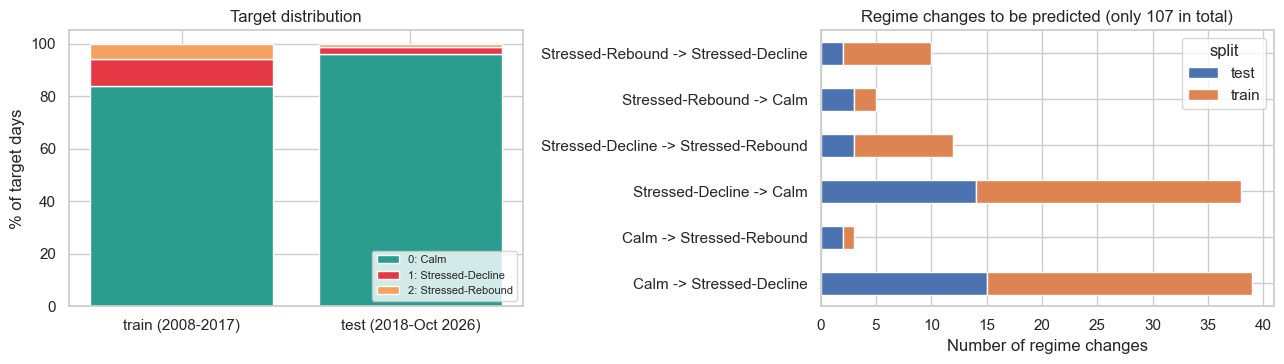

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
share = pd.DataFrame({"train": tr_["target_next_regime"].value_counts(normalize=True).sort_index(), "test": te_["target_next_regime"].value_counts(normalize=True).sort_index()}).fillna(0) * 100
bottom = np.zeros(2)
for k in CLASSES:
    ax[0].bar(["train (2008-2017)", "test (2018-Oct 2026)"], share.loc[k].to_numpy(), bottom=bottom, color=COLORS[k], label=f"{k}: {REGIME_NAMES[k]}")
    bottom += share.loc[k].to_numpy()
ax[0].set_ylabel("% of target days"); ax[0].set_title("Target distribution"); ax[0].legend(loc="lower right", fontsize=8)
trans_counts = pairs.loc[pairs["current_regime"] != pairs["target_next_regime"]].groupby(["change", "split"]).size().unstack(fill_value=0)
trans_counts.plot(kind="barh", stacked=True, ax=ax[1], color=["#4c72b0", "#dd8452"])
ax[1].set_xlabel("Number of regime changes"); ax[1].set_ylabel(""); ax[1].set_title("Regime changes to be predicted (only 107 in total)")
save_fig("target_distribution")


**Interpretation:**
- **No missing values or duplicates, and the order is chronological.** All three classes appear in both periods, so a per-class evaluation is possible in both.
- **Strong imbalance, and it shifts between periods.** Calm is 83.8% of training targets and 95.9% of test targets. The stressed regimes are 16.2% of training samples (378) but only 4.1% of test samples (90), and Stressed-Rebound has just **27 test days (1.2%)**. Any per-class result for Stressed-Rebound in the test period rests on 27 samples from one episode.
- **There are very few regime changes to learn from or to predict:** 68 in training (2.9% of sessions) and 39 in the test period (1.8%). Of the 39 test changes, 17 are entries into a stressed regime from Calm and 22 start from an already-stressed regime.
- **Persistence is already hard to beat.** It is right on 97.1% of training samples and 98.2% of test samples, higher in the test period because stress was rarer. This confirms the Phase 7 finding and sets the bar: any model must find something in the 39 changes that "tomorrow = today" cannot.


## 5. Feature selection

**Objective:** decide which day-*t* variables go into the classifier, and make sure none of them contains information from after the close of day *t*.

All candidates are functions of the Phase 5 feature table at day *t*. Phase 5 already enforced the look-ahead rule: rolling windows look backwards, and the global series (S&P 500, US 10Y, USD/INR, gold, Brent) are shifted by one day.

| Candidate | Content | Relevance | Leakage / redundancy |
|---|---|---|---|
| **A. PCA scores** (`pc1` to `pc9`) | Phase 6 scaler + PCA applied to the 21 features at *t* | The same 9-dimensional space where the regimes were defined; PC1 is the stress axis and PC2 the trend axis (Phase 6). Decorrelated by construction. | No look-ahead: the Phase 6 scaler and PCA were fitted on 2008-2017 only and are applied unchanged to the test period. No redundancy between components. |
| **B. PCA scores + current regime** (`pc1`..`pc9` + one-hot of `R(t)`) | A plus which regime the market is in today | Persistence carries most of the information about tomorrow (97.6%); giving it to the model explicitly lets it learn *when to depart from persistence*. | `R(t)` is known at the close of *t*, so it is legitimate. But it is a deterministic function of the PCs, so it adds no new market information, only an easier way to express it. It is the variable that makes the persistence baseline a special case of the model. |
| **C. Original 21 standardised features** | `features.csv` columns scaled with the Phase 6 scaler | Directly interpretable (VIX, volatility, drawdown, ...) | Correlated groups (10/21/63-day volatility, VIX, drawdown, correlation) would be counted several times by distance-based models; this is why Phase 6 used PCA. |
| **D. Original 21 standardised features + current regime** | C plus the one-hot of `R(t)` | The interpretable version of B | Same redundancy as C; same status of `R(t)` as in B. Added so that the "current regime" question and the "PCA or original features" question are tested separately and fairly. |

**Not used, and why:**
- **Both original features and PCA scores together:** pure redundancy (the PCs are linear combinations of the same 21 variables).
- **Distances to the K-Means centres, or margin to the cluster boundary:** these would encode the regime rule itself. They are legitimate day-*t* quantities and would be a natural way to anticipate boundary crossings, but they add a hand-built layer of engineering that goes beyond the project outline. I did not include them; this is a limitation noted in the final report.
- **Any variable dated *t+1* or later**, including the target-day regime, the future return, forward volatility (Phase 7's "independent evidence" variables), or `regime_name` (a relabelling of the target's neighbour): all excluded.
- **Identifiers and non-features:** `split`, dates, `nifty_close`, `risk_free_daily` and `regime_name`.
- **Sensex, sectors and individual stocks:** not part of the Phase 5 feature set.

**How the choice is made:** A, B, C and D are compared on the **training period only** with chronological cross-validation (Section 8), using the same models and the same small grids for each. The feature set with the best average validation macro-F1 is used for everything that follows. This is a decision from data, but each candidate is also financially sensible, so the choice is not made on performance alone.

In [6]:
CUR_COLS = [f"cur_{k}" for k in CLASSES]

def build_design_matrix(feature_frame, current_regime):
    """Day-t inputs for every candidate feature set. Uses only the saved Phase 6 scaler and PCA (transform only)."""
    z = pd.DataFrame(scaler_p6.transform(feature_frame[FEATURE_COLS]), index=feature_frame.index, columns=FEATURE_COLS)
    pcs = pd.DataFrame(pca_p6.transform(z.to_numpy()), index=feature_frame.index, columns=PC_COLS)
    cur = pd.get_dummies(current_regime.astype(int)).reindex(columns=CLASSES, fill_value=0).astype(float)
    cur.columns = CUR_COLS
    return {"A: PCA scores": pcs, "B: PCA scores + current regime": pcs.join(cur), "C: 21 standardised features": z,
            "D: 21 standardised features + current regime": z.join(cur)}

design = build_design_matrix(features.loc[dataset.index], dataset["current_regime"])
for name, X in design.items():
    assert X.index.equals(dataset.index) and X.notna().all().all()
    print(f"{name:34s} shape {X.shape}")

# leakage canary: an input that smuggled in information from t+1 would correlate MORE with tomorrow's regime than with today's.
# Every legitimate day-t input should correlate at least as strongly with today's regime (the regime is a function of day-t features).
all_inputs = pd.concat(design.values(), axis=1)
all_inputs = all_inputs.loc[:, ~all_inputs.columns.duplicated()]
assert all_inputs.index.equals(dataset.index)
corr_next = all_inputs.corrwith(dataset["target_next_regime"]).abs()
corr_today = all_inputs.corrwith(dataset["current_regime"]).abs()
canary = pd.DataFrame({"|corr| with today's regime": corr_today, "|corr| with tomorrow's regime": corr_next})
canary["tomorrow minus today"] = canary.iloc[:, 1] - canary.iloc[:, 0]
print("Largest value of (|corr with tomorrow| - |corr with today|) over all", len(canary), "inputs:", round(float(canary["tomorrow minus today"].max()), 4))
display(canary.sort_values("tomorrow minus today", ascending=False).head(5).round(3))
# weak inputs (e.g. pc7, pc9) correlate with the label at about 0.02-0.06, so differences of a few thousandths are noise; a real leak would show a large positive gap
assert (canary["tomorrow minus today"] <= 0.02).all(), "an input is clearly more related to tomorrow than to today: possible look-ahead"

# structural spot-check: each design-matrix row equals an independent transformation of that same date's raw feature row (never of t+1)
rng_chk = np.random.default_rng(SEED)
for t in rng_chk.choice(dataset.index, 40, replace=False):
    z_row = scaler_p6.transform(features.loc[[t], FEATURE_COLS]); pc_row = pca_p6.transform(z_row)[0]
    assert np.allclose(design["A: PCA scores"].loc[t].to_numpy(), pc_row) and np.allclose(design["C: 21 standardised features"].loc[t].to_numpy(), z_row[0])
    assert design["B: PCA scores + current regime"].loc[t, CUR_COLS].to_numpy().argmax() == dataset.loc[t, "current_regime"]
    assert design["D: 21 standardised features + current regime"].loc[t, CUR_COLS].to_numpy().argmax() == dataset.loc[t, "current_regime"]
print("Structural check passed: 40 random rows of every design matrix equal the transformation of that date's own features and current regime.")

A: PCA scores                      shape (4508, 9)
B: PCA scores + current regime     shape (4508, 12)
C: 21 standardised features        shape (4508, 21)
D: 21 standardised features + current regime shape (4508, 24)
Largest value of (|corr with tomorrow| - |corr with today|) over all 33 inputs: 0.0076


,|corr| with today's regime,|corr| with tomorrow's regime,tomorrow minus today
pc7,0.018,0.026,0.008
nifty_skew_63d,0.131,0.139,0.007
banknifty_rel_21d,0.036,0.042,0.006
nifty_ret_21d,0.031,0.037,0.006
pc9,0.055,0.060,0.005


Structural check passed: 40 random rows of every design matrix equal the transformation of that date's own features and current regime.



**Interpretation:** the four candidate input sets have the expected shapes (9, 12, 21 and 24 columns). The leakage checks passed in two ways. (1) The structural spot-check shows that each design-matrix row equals the Phase 6 transformation of that same date's feature row and current regime, never of a later row. (2) The correlation canary found no input that relates more strongly to tomorrow's regime than to today's: the largest gap is +0.008, on `pc7`, whose correlation with the label is only about 0.02 to 0.03, so this is noise; the informative inputs (`pc1`, `pc2`, the current-regime indicators) all correlate *less* with tomorrow than with today, which is the expected decay of persistence. This is a coarse check and not a proof; the timing guarantee comes from the construction in Section 3 and from Phase 5.


## 6. Train/validation/test strategy

**Three roles, three sets of rows:**

| Role | Rows | Used for |
|---|---|---|
| Training | targets 2008-06-10 to 2017-12-29 (2,335 samples) | Fitting models; *inside* it, expanding-window folds provide **validation** data for model selection |
| Validation | Later slices of the training period | Choosing the feature set, hyperparameters and the ensemble members |
| Test | targets 2018-01-02 to 2026-10-27 (2,173 samples) | Final held-out evaluation, used once |

**Method:** `TimeSeriesSplit(n_splits=8)`: each fold trains on all rows up to a date and validates on the next block. We report metrics on the **pooled out-of-fold predictions** from all folds.

**Why this and not random K-fold:** the inputs are 10, 21 and 63-day rolling windows, so neighbouring days are nearly identical; random folds would put a day in training and its twin in validation, inflating scores. Random folds would also train on the future (e.g. a 2013 model that has seen 2020). Expanding-window folds reproduce live use: always fit on the past, predict the next block.

**Why 8 folds:** with only 2,335 samples and a handful of regime episodes, fewer folds would leave the first training block too large. With 8 folds the first block ends in July 2009, so the first validation block (Jul 2009 to Jul 2010) still contains the tail of the Stressed-Rebound episode.

**Limitations that must be remembered:**
1. **Stressed-Rebound exists only in 2008-09.** After the first fold no validation block contains it, so tuning can barely see this class (26 pooled validation days). The same is true of Stressed-Decline: most of its days are in 2008-09 too.
2. **The labels are in-sample.** The Phase 6 K-Means, scaler and PCA were fitted on all of 2008-2017, including the validation blocks. So validation scores inside the training period are optimistic about the regime definition. They are valid for *comparing* models and settings against each other and against persistence on the same rows, which is how they are used. Only the test period is truly out-of-sample.
3. **No gap** between training and validation is used. The row immediately before a validation block has as its label the regime of the first validation day, which would be known at that day's close in live use, so this does not leak.

In [7]:
Y = dataset["target_next_regime"]
X_dev = {name: X.loc[tr_.index] for name, X in design.items()}               # development (training-period) inputs
y_dev, cur_dev = Y.loc[tr_.index], dataset.loc[tr_.index, "current_regime"]

tscv = TimeSeriesSplit(n_splits=N_SPLITS)
SPLITS = list(tscv.split(y_dev))
fold_rows = []
for i, (a, b) in enumerate(SPLITS):
    vc = y_dev.iloc[b].value_counts()
    fold_rows.append({"fold": i + 1, "train rows": len(a), "train from": y_dev.index[a[0]].date(), "train to": y_dev.index[a[-1]].date(),
                      "validation from": y_dev.index[b[0]].date(), "validation to": y_dev.index[b[-1]].date(),
                      **{f"val {REGIME_NAMES[k]}": int(vc.get(k, 0)) for k in CLASSES},
                      "val changes": int((y_dev.iloc[b] != cur_dev.iloc[b]).sum())})
display(pd.DataFrame(fold_rows).set_index("fold"))
va_all = np.concatenate([b for _, b in SPLITS])
print("Pooled validation rows:", len(va_all), "| the first", len(y_dev) - len(va_all), "rows are only ever used for training")
print("Pooled validation class counts:", y_dev.iloc[va_all].value_counts().sort_index().to_dict(), "| changes:", int((y_dev.iloc[va_all] != cur_dev.iloc[va_all]).sum()))

,train rows,train from,train to,validation from,validation to,val Calm,val Stressed-Decline,val Stressed-Rebound,val changes
fold,,,,,,,,,
1,263,2008-06-09,2009-07-10,2009-07-13,2010-07-29,211,22,26,19
2,522,2008-06-09,2010-07-29,2010-07-30,2011-08-11,252,7,0,3
3,781,2008-06-09,2011-08-11,2011-08-12,2012-09-07,225,34,0,13
4,1040,2008-06-09,2012-09-07,2012-09-10,2013-09-30,244,15,0,4
5,1299,2008-06-09,2013-09-30,2013-10-01,2014-10-29,259,0,0,0
6,1558,2008-06-09,2014-10-29,2014-10-30,2015-11-20,243,16,0,4
7,1817,2008-06-09,2015-11-20,2015-11-23,2016-12-14,256,3,0,4
8,2076,2008-06-09,2016-12-14,2016-12-15,2017-12-28,259,0,0,0


Pooled validation rows: 2072 | the first 263 rows are only ever used for training
Pooled validation class counts: {0: 1949, 1: 97, 2: 26} | changes: 47



**Interpretation:**
- The first fold's validation block (July 2009 to July 2010) is the only one that contains Stressed-Rebound (26 days), and it holds 19 of the 47 regime changes in the pooled validation data. Folds 5 and 8 contain no stressed days at all.
- This means model selection is informed mostly by one episode (the tail of the 2008-09 crisis), plus smaller stress episodes in 2011, 2013 and 2015. **Validation scores are noisy and should be read as indicative**; differences of a few hundredths of macro-F1 between models are within what this limited validation can resolve.
- Persistence is evaluated on exactly the same pooled rows (Section 7), so the comparison with the models is like for like.


## 7. Baselines, candidate models and evaluation metrics

### 7.1 The baselines

- **Regime persistence:** `R_hat(t+1) = R(t)`. This is the benchmark that matters. A forecaster that cannot beat it has learned nothing about regime *changes*, because persistence is already right on 97.6% of days. By construction it **never predicts a change**, so its recall on transition days is exactly zero; any model with real skill must at least do better there without paying too much in false alarms.
- **Always Calm:** a reference that shows the accuracy trap. It is right on about 96% of test days while ignoring both stressed regimes.

### 7.2 Candidate models (the set specified in the outline: Logistic Regression, kNN, SVM, Random Forest, then a Voting ensemble)

| Model | How it works (briefly) | Why it is suitable here | Main limitation here | Alternatives not used |
|---|---|---|---|---|
| **Logistic Regression** (multinomial, L2) | Linear scores for each class turned into probabilities | Interpretable coefficients; a sensible linear model when the regimes are a nearest-centre partition of a smooth feature space; works with few stressed samples | Cannot represent non-linear boundaries; calibrated probabilities need enough minority data | Penalised variants (L1/elastic net) add a hyperparameter with little gain on 12 inputs |
| **k-Nearest Neighbours** | Votes among the *k* most similar past days | Matches the idea of a regime as a neighbourhood; no training assumption | Sensitive to scaling; neighbours of a crisis day are mostly in 2008-09, so it cannot extrapolate to a new crisis | Radius-based neighbours behave poorly with very different local density |
| **SVM** (RBF kernel) | Maximum-margin boundary in a kernel space | Flexible smooth non-linear boundary with few parameters; good with small samples | Hard to interpret; probabilities need an internal calibration step | Linear SVM is almost the same as logistic regression |
| **Random Forest** | Many decorrelated decision trees vote | Handles non-linearity and interactions, little sensitivity to scaling, gives importances | Axis-aligned splits are a poor match for K-Means' diagonal boundaries; cannot extrapolate beyond training ranges | Gradient boosting is more tuning-heavy and more prone to overfit ~100 events |
| **Soft Voting ensemble** | Average the class probabilities of the best models | Reduces the variance of individual models | Inherits what the members share; averaging cannot create skill that none of them has | Stacking adds another learned layer with too few events to support it |

**Not selected:** neural networks, boosting and sequence models (LSTM, HMM): with **107 regime changes in the whole sample**, flexible models cannot be reliably fitted or validated, and the project scope is the set above.

### 7.3 Hyperparameters

Small grids only, to avoid overfitting a validation set that contains very few events:

| Model | Grid |
|---|---|
| Logistic Regression | `C` in {0.01, 0.1, 1, 10}; `class_weight` in {none, balanced} |
| kNN | `n_neighbors` in {5, 15, 31, 61}; `weights` in {uniform, distance} |
| SVM (RBF) | `C` in {0.1, 1, 10}; `class_weight` in {none, balanced}; `gamma="scale"` |
| Random Forest | 300 trees; `max_depth` in {3, 6, 12}; `min_samples_leaf` in {5, 20}; `class_weight` in {none, balanced_subsample} |

`class_weight="balanced"` is included because the stressed regimes are 10.4% of training days. LR, kNN and SVM sit in a pipeline with a `StandardScaler` that is **fitted inside each training fold** (distance-based models need comparable scales; this is where scaling is learned, never on the full data). Random Forest does not need scaling.

**Selection metric:** pooled out-of-fold **macro-F1** (average of the three per-class F1 scores, so the small classes count as much as Calm); ties broken by balanced accuracy.

### 7.4 Evaluation metrics

| Metric | What it tells us here |
|---|---|
| Accuracy | Share of correct days. Misleading here (Always Calm already scores about 96%). Reported, not used for decisions |
| Balanced accuracy | Mean per-class recall: how often each regime is recognised |
| Precision / recall / F1 (per class) | Which regimes are recognised and which are confused |
| **Macro-F1** | Primary metric: each regime counts equally |
| Weighted F1 | F1 weighted by class frequency (dominated by Calm; shown for completeness) |
| Confusion matrix | Which regimes get confused with which |
| **Transition metrics** (Section 11) | Whether the model anticipates *changes*, which persistence cannot do at all |

In [8]:
MODEL_KINDS = ["Logistic Regression", "kNN", "SVM", "Random Forest"]
GRIDS = {
    "Logistic Regression": [{"C": c, "class_weight": w} for c in (0.01, 0.1, 1, 10) for w in (None, "balanced")],
    "kNN": [{"n_neighbors": k, "weights": w} for k in (5, 15, 31, 61) for w in ("uniform", "distance")],
    "SVM": [{"C": c, "class_weight": w} for c in (0.1, 1, 10) for w in (None, "balanced")],
    "Random Forest": [{"max_depth": d, "min_samples_leaf": l, "class_weight": w} for d in (3, 6, 12) for l in (5, 20) for w in (None, "balanced_subsample")],
}

def make_model(kind, params, proba=False):
    if kind == "Logistic Regression":
        return Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=5000, random_state=SEED, **params))])
    if kind == "kNN":
        return Pipeline([("scale", StandardScaler()), ("clf", KNeighborsClassifier(**params))])
    if kind == "SVM":
        return Pipeline([("scale", StandardScaler()), ("clf", SVC(kernel="rbf", gamma="scale", probability=proba, random_state=SEED, **params))])
    if kind == "Random Forest":
        return RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1, **params)
    raise ValueError(kind)

def class_scores(y_true, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=CLASSES, zero_division=0)
    return pd.DataFrame({"precision": p, "recall": r, "f1": f, "support": s}, index=[REGIME_NAMES[k] for k in CLASSES])

def score_all(y_true, y_pred, y_cur):
    y_true, y_pred, y_cur = (np.asarray(v) for v in (y_true, y_pred, y_cur))
    chg, stay = y_true != y_cur, y_true == y_cur
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_precision": precision_recall_fscore_support(y_true, y_pred, labels=CLASSES, average="macro", zero_division=0)[0],
        "macro_recall": precision_recall_fscore_support(y_true, y_pred, labels=CLASSES, average="macro", zero_division=0)[1],
        "macro_f1": f1_score(y_true, y_pred, labels=CLASSES, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, labels=CLASSES, average="weighted", zero_division=0),
        "change_recall": float((y_pred[chg] == y_true[chg]).mean()) if chg.any() else np.nan,
        "false_alarm_rate": float((y_pred[stay] != y_cur[stay]).mean()),
    }

def chrono_oof_predict(make, X, y):
    """Pooled out-of-fold predictions from the expanding-window folds (models are refitted on each training block)."""
    pred = np.full(len(y), -1)
    for a, b in SPLITS:
        m = make(); m.fit(X.iloc[a], y.iloc[a]); pred[b] = m.predict(X.iloc[b])
    return pred

# reference rows for the baselines on the same pooled validation rows
y_va, cur_va = y_dev.iloc[va_all].to_numpy(), cur_dev.iloc[va_all].to_numpy()
persist_cv = score_all(y_va, cur_va, cur_va)
alwayscalm_cv = score_all(y_va, np.zeros_like(y_va), cur_va)
print("Validation baselines on the same pooled rows:")
display(pd.DataFrame({"Persistence": persist_cv, "Always Calm": alwayscalm_cv}).T.round(3))

Validation baselines on the same pooled rows:


,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,change_recall,false_alarm_rate
Persistence,0.977,0.895,0.892,0.895,0.894,0.977,0.000,0.000
Always Calm,0.941,0.333,0.314,0.333,0.323,0.912,0.489,0.049


## 8. Feature-set comparison and hyperparameter tuning (training period only)

**Objective:** for each of the four model types and each candidate feature set (A, B, C), find the best setting from its small grid by pooled chronological validation, then compare feature sets by their average best validation macro-F1.

**Scaling check (informational):** does re-scaling the inputs change results? It matters for choosing a pipeline: the one-hot columns of feature set B have a much smaller spread than the PCA scores.

In [9]:
rows = []
for fs_name, X in X_dev.items():
    for kind in MODEL_KINDS:
        for params in GRIDS[kind]:
            pred = chrono_oof_predict(lambda: make_model(kind, params), X, y_dev)
            s = score_all(y_va, pred[va_all], cur_va)
            rows.append({"feature_set": fs_name, "model": kind, "params": json.dumps(params), **s})
cv_results = pd.DataFrame(rows)
print("Grid fits completed:", len(cv_results), "settings x", N_SPLITS, "folds")

best = (cv_results.sort_values(["macro_f1", "balanced_accuracy"], ascending=False)
        .groupby(["feature_set", "model"], sort=False).head(1))
tab = best.pivot(index="model", columns="feature_set", values="macro_f1").reindex(MODEL_KINDS)
tab.loc["MEAN of the four"] = tab.mean()
tab.loc["Persistence (reference)"] = persist_cv["macro_f1"]
display(tab.round(3))
FEATURE_SET = tab.loc["MEAN of the four"].idxmax()
print("\nChosen feature set (highest mean best-validation macro-F1):", FEATURE_SET)

Grid fits completed: 136 settings x 8 folds


feature_set,A: PCA scores,B: PCA scores + current regime,C: 21 standardised features,D: 21 standardised features + current regime
model,,,,
Logistic Regression,0.618,0.894,0.745,0.894
kNN,0.632,0.871,0.670,0.828
SVM,0.652,0.849,0.673,0.830
Random Forest,0.658,0.772,0.585,0.621
MEAN of the four,0.640,0.846,0.668,0.793
Persistence (reference),0.894,0.894,0.894,0.894



Chosen feature set (highest mean best-validation macro-F1): B: PCA scores + current regime


In [10]:
# Informational: the same comparison for feature set B with and without scaling the inputs (reference settings only)
ref = {"Logistic Regression": {"C": 1, "class_weight": "balanced"}, "kNN": {"n_neighbors": 15, "weights": "uniform"}, "SVM": {"C": 10, "class_weight": "balanced"}}
rows = []
for kind, params in ref.items():
    pred_s = chrono_oof_predict(lambda: make_model(kind, params), X_dev["B: PCA scores + current regime"], y_dev)
    raw = {"Logistic Regression": lambda: LogisticRegression(max_iter=5000, random_state=SEED, **params), "kNN": lambda: KNeighborsClassifier(**params),
           "SVM": lambda: SVC(kernel="rbf", gamma="scale", random_state=SEED, **params)}[kind]
    pred_u = chrono_oof_predict(raw, X_dev["B: PCA scores + current regime"], y_dev)
    rows.append({"model": kind, "macro-F1 with StandardScaler": f1_score(y_va, pred_s[va_all], labels=CLASSES, average="macro", zero_division=0),
                 "macro-F1 without scaling": f1_score(y_va, pred_u[va_all], labels=CLASSES, average="macro", zero_division=0)})
display(pd.DataFrame(rows).set_index("model").round(3))

,macro-F1 with StandardScaler,macro-F1 without scaling
model,,
Logistic Regression,0.833,0.690
kNN,0.726,0.615
SVM,0.715,0.623


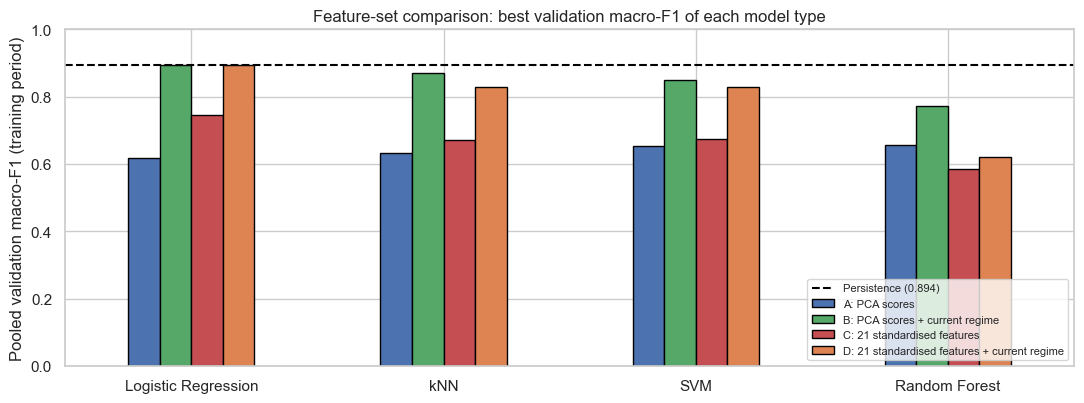

In [11]:
fs_plot = best.pivot(index="model", columns="feature_set", values="macro_f1").reindex(MODEL_KINDS)
fig, ax = plt.subplots(figsize=(11, 4.2))
fs_plot.plot(kind="bar", ax=ax, color=["#4c72b0", "#55a868", "#c44e52", "#dd8452"], edgecolor="black")
ax.axhline(persist_cv["macro_f1"], color="black", ls="--", lw=1.5, label=f"Persistence ({persist_cv['macro_f1']:.3f})")
ax.set_ylabel("Pooled validation macro-F1 (training period)"); ax.set_xlabel(""); ax.set_ylim(0, 1)
ax.set_title("Feature-set comparison: best validation macro-F1 of each model type"); ax.legend(loc="lower right", fontsize=8); ax.tick_params(axis="x", rotation=0)
save_fig("feature_set_comparison")


**Interpretation (feature sets, scaling and what they say about the problem):**

| Best validation macro-F1 | A: PCs | B: PCs + current regime | C: 21 features | D: 21 features + current regime |
|---|---|---|---|---|
| Mean over the four model types | 0.640 | **0.846** | 0.668 | 0.793 |

Persistence scores **0.894** on the same rows.

- **No model beats persistence on the validation folds under any feature set.** The best result of any model is 0.894 (Logistic Regression on B or D), which is persistence itself (its predictions never differ from today's regime; see the next table).
- **Without the current regime (A and C), models are far below persistence (0.58 to 0.75).** They have to rediscover today's regime from continuous inputs, and they make mistakes near the cluster boundaries, which is where most regime changes occur. This is a useful finding: **the continuous market features add little over knowing today's regime**, and the regime label itself carries most of what can be learned.
- **Adding the current regime closes most of the gap.** It makes persistence a special case of the model class, so the remaining question is whether anything can be learned on top of it. B is better than D on average (0.846 against 0.793), driven by kNN, SVM and Random Forest; Logistic Regression is equal. B is therefore chosen, which also keeps continuity with Phase 6 (the classifier works in the PCA space in which the regimes were defined).
- **Scaling matters, and for a revealing reason:** standardising the inputs raises Logistic Regression from 0.690 to 0.833, kNN from 0.615 to 0.726 and SVM from 0.623 to 0.715 on feature set B. Standardising gives the 0/1 current-regime columns a weight comparable to the PCs. The models do better when the current regime is allowed to dominate, which is consistent with the picture above.
- PCA scores did *not* beat the original standardised features when neither included the current regime (A 0.640 against C 0.668), so the use of PCs is justified by continuity and decorrelation, not by a better score.


### Tuned settings and the Voting ensemble

For the chosen feature set, the best setting of each model type is taken from the grid by validation macro-F1. The **Voting ensemble** (soft voting, i.e. averaging predicted probabilities) combines the **three best** individual models by validation macro-F1, as the outline specifies "the best models".

In [12]:
chosen = (cv_results[cv_results["feature_set"] == FEATURE_SET].sort_values(["macro_f1", "balanced_accuracy"], ascending=False)
          .groupby("model", sort=False).head(1).set_index("model").reindex(MODEL_KINDS))
BEST_PARAMS = {m: json.loads(chosen.loc[m, "params"]) for m in MODEL_KINDS}
sel = chosen[["params", "accuracy", "balanced_accuracy", "macro_f1", "weighted_f1", "change_recall", "false_alarm_rate"]].copy()
print("SELECTED SETTINGS (pooled chronological validation, training period only), feature set:", FEATURE_SET)
display(sel.round(3))

# the full grid for the record, and how flat it is
spread = cv_results[cv_results["feature_set"] == FEATURE_SET].groupby("model")["macro_f1"].agg(["min", "median", "max"]).reindex(MODEL_KINDS)
print("Spread of validation macro-F1 across each grid (a flat grid means tuning mattered little):")
display(spread.round(3))

ENSEMBLE_MEMBERS = list(chosen["macro_f1"].sort_values(ascending=False).index[:3])
print("Voting ensemble members (top 3 by validation macro-F1):", ENSEMBLE_MEMBERS)

def make_voting():
    return VotingClassifier([(m.replace(" ", "_"), make_model(m, BEST_PARAMS[m], proba=True)) for m in ENSEMBLE_MEMBERS], voting="soft")

pred_vote = chrono_oof_predict(make_voting, X_dev[FEATURE_SET], y_dev)
vote_cv = score_all(y_va, pred_vote[va_all], cur_va)
cv_summary = pd.DataFrame({**{m: score_all(y_va, chrono_oof_predict(lambda m=m: make_model(m, BEST_PARAMS[m]), X_dev[FEATURE_SET], y_dev)[va_all], cur_va) for m in MODEL_KINDS},
                           "Voting (soft)": vote_cv, "Persistence": persist_cv, "Always Calm": alwayscalm_cv}).T
print("\nVALIDATION SUMMARY (pooled out-of-fold, training period; test period not used)")
display(cv_summary.round(3))

SELECTED SETTINGS (pooled chronological validation, training period only), feature set: B: PCA scores + current regime


,params,accuracy,balanced_accuracy,macro_f1,weighted_f1,change_recall,false_alarm_rate
model,,,,,,,
Logistic Regression,"{""C"": 0.01, ""class_weight"": ""balanced""}",0.977,0.895,0.894,0.977,0.000,0.000
kNN,"{""n_neighbors"": 5, ""weights"": ""uniform""}",0.969,0.889,0.871,0.970,0.043,0.009
SVM,"{""C"": 0.1, ""class_weight"": ""balanced""}",0.958,0.895,0.849,0.962,0.043,0.020
Random Forest,"{""max_depth"": 12, ""min_samples_leaf"": 5, ""class_weight"": ""balanced_subsample""}",0.941,0.892,0.772,0.948,0.064,0.039


Spread of validation macro-F1 across each grid (a flat grid means tuning mattered little):


,min,median,max
model,,,
Logistic Regression,0.754,0.767,0.894
kNN,0.712,0.740,0.871
SVM,0.715,0.786,0.849
Random Forest,0.694,0.713,0.772


Voting ensemble members (top 3 by validation macro-F1): ['Logistic Regression', 'kNN', 'SVM']

VALIDATION SUMMARY (pooled out-of-fold, training period; test period not used)


,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,change_recall,false_alarm_rate
Logistic Regression,0.977,0.895,0.892,0.895,0.894,0.977,0.000,0.000
kNN,0.969,0.889,0.855,0.889,0.871,0.970,0.043,0.009
SVM,0.958,0.895,0.820,0.895,0.849,0.962,0.043,0.020
Random Forest,0.941,0.892,0.700,0.892,0.772,0.948,0.064,0.039
Voting (soft),0.976,0.894,0.887,0.894,0.891,0.977,0.000,0.001
Persistence,0.977,0.895,0.892,0.895,0.894,0.977,0.000,0.000
Always Calm,0.941,0.333,0.314,0.333,0.323,0.912,0.489,0.049



**Interpretation (tuning and the ensemble):**
- **The tuned Logistic Regression is persistence.** The best setting (`C = 0.01`, balanced weights, the strongest regularisation in the grid) has validation change recall 0 and false-alarm rate 0: it always predicts today's regime. Its macro-F1 of 0.894 equals persistence to three decimals.
- **The other models are slightly worse than persistence:** kNN 0.871, SVM 0.849, Random Forest 0.772. Their small non-zero change recall (4% to 6%) is bought with false alarms (1% to 4% of stay days), and with only about 100 stressed days in validation these false alarms cost more in precision than the few correct changes gain in recall.
- **Tuning mattered little and the selected settings sit at the edges of their grids** (smallest `C` for Logistic Regression and SVM, smallest `k` for kNN, deepest trees for the forest). For Logistic Regression and SVM, a smaller `C` means *more* regularisation, i.e. closer to persistence, so extending the grid would not change the conclusion; I did not widen the grids to avoid more tuning on a validation set with 47 changes.
- **The Voting ensemble combines Logistic Regression, kNN and SVM** (the Random Forest ranks last and is excluded). Its validation macro-F1 is 0.891, again at or just below persistence, which is what averaging a persistence-like model with two slightly worse ones would give.
- **Conclusion for the test evaluation:** going into Section 10, the validation evidence says that the best a model can do is match persistence. The test period is a fair out-of-sample check of this.


## 9. Final fit on the full training period

The selected settings are refitted once on **all 2,335 training samples** (feature set and hyperparameters fixed by Section 8). The test samples are only passed through `.predict()` and `.predict_proba()`. Nothing is refitted on test data.

In [13]:
X_train, X_test = design[FEATURE_SET].loc[tr_.index], design[FEATURE_SET].loc[te_.index]
y_train, y_test = tr_["target_next_regime"], te_["target_next_regime"]
cur_test = te_["current_regime"]
assert X_train.index.max() < X_test.index.min() and len(X_test) == 2173

final_models = {}
for kind in MODEL_KINDS:
    final_models[kind] = make_model(kind, BEST_PARAMS[kind], proba=True).fit(X_train, y_train)          # probability=True only matters for SVM
final_models["Voting (soft)"] = make_voting().fit(X_train, y_train)

pred = {"Persistence": cur_test.to_numpy(), "Always Calm": np.zeros(len(y_test), dtype=int)}
proba = {}
for name, m in final_models.items():
    pred[name] = m.predict(X_test)
    proba[name] = pd.DataFrame(m.predict_proba(X_test), index=X_test.index, columns=[f"p_{REGIME_NAMES[k]}" for k in m.classes_])
    assert list(m.classes_) == CLASSES
print("Fitted:", list(final_models), "| test rows:", len(X_test))

Fitted: ['Logistic Regression', 'kNN', 'SVM', 'Random Forest', 'Voting (soft)'] | test rows: 2173


## 10. Evaluation on the held-out test period

**Objective:** measure every model against persistence on the **same** 2,173 test samples, with metrics that do not hide the small regimes.

**Uncertainty:** the test set has only 90 stressed days and 39 regime changes, from basically one episode (2020). A point estimate would overstate our precision, so the **difference in macro-F1 versus persistence** is given with a 95% interval from a paired **circular block bootstrap** (blocks of 21 sessions, 1,000 draws, same resample for the model and for persistence). It captures sampling variation, not the fact that there is only one big crisis in the test period.

In [14]:
MODEL_ORDER = ["Persistence", "Always Calm"] + MODEL_KINDS + ["Voting (soft)"]
y_t, c_t = y_test.to_numpy(), cur_test.to_numpy()

def macro_f1_fast(y, p):
    cm = np.bincount(y * 3 + p, minlength=9).reshape(3, 3)
    tp = np.diag(cm).astype(float); fp = cm.sum(axis=0) - tp; fn = cm.sum(axis=1) - tp
    denom = 2 * tp + fp + fn
    return float(np.mean(np.where(denom > 0, 2 * tp / np.where(denom > 0, denom, 1), 0)))

def paired_block_bootstrap(y, p_model, p_base, B=1000, block=21, seed=SEED):
    rng = np.random.default_rng(seed); n = len(y); nb = int(np.ceil(n / block)); d = np.empty(B)
    for b in range(B):
        idx = ((rng.integers(0, n, nb)[:, None] + np.arange(block)[None, :]) % n).ravel()[:n]
        d[b] = macro_f1_fast(y[idx], p_model[idx]) - macro_f1_fast(y[idx], p_base[idx])
    return float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5)), float((d > 0).mean())

rows = {}
for name in MODEL_ORDER:
    s = score_all(y_t, pred[name], c_t)
    if name not in ("Persistence", "Always Calm"):
        lo, hi, pgt = paired_block_bootstrap(y_t, pred[name], pred["Persistence"])
        s.update({"delta_macro_f1_vs_persistence": s["macro_f1"] - score_all(y_t, pred["Persistence"], c_t)["macro_f1"], "ci_low": lo, "ci_high": hi, "share_draws_better": pgt})
    rows[name] = s
test_metrics = pd.DataFrame(rows).T
show = test_metrics[["accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1"]].copy()
show["delta macro-F1 vs persistence [95% CI]"] = [("" if n in ("Persistence", "Always Calm") else f"{test_metrics.loc[n, 'delta_macro_f1_vs_persistence']:+.3f}  [{test_metrics.loc[n, 'ci_low']:+.3f}, {test_metrics.loc[n, 'ci_high']:+.3f}]") for n in show.index]
print("TEST-PERIOD METRICS (2,173 samples; the same rows for every row of this table)")
display(show.round(3))

TEST-PERIOD METRICS (2,173 samples; the same rows for every row of this table)


,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,delta macro-F1 vs persistence [95% CI]
Persistence,0.982,0.846,0.846,0.846,0.846,0.982,
Always Calm,0.959,0.333,0.320,0.333,0.326,0.938,
Logistic Regression,0.982,0.846,0.846,0.846,0.846,0.982,"+0.000 [+0.000, +0.000]"
kNN,0.983,0.846,0.860,0.846,0.853,0.983,"+0.007 [+0.000, +0.032]"
SVM,0.940,0.841,0.702,0.841,0.738,0.952,"-0.108 [-0.165, -0.045]"
Random Forest,0.982,0.851,0.843,0.851,0.847,0.982,"+0.001 [-0.007, +0.014]"
Voting (soft),0.982,0.846,0.846,0.846,0.846,0.982,"+0.000 [+0.000, +0.000]"


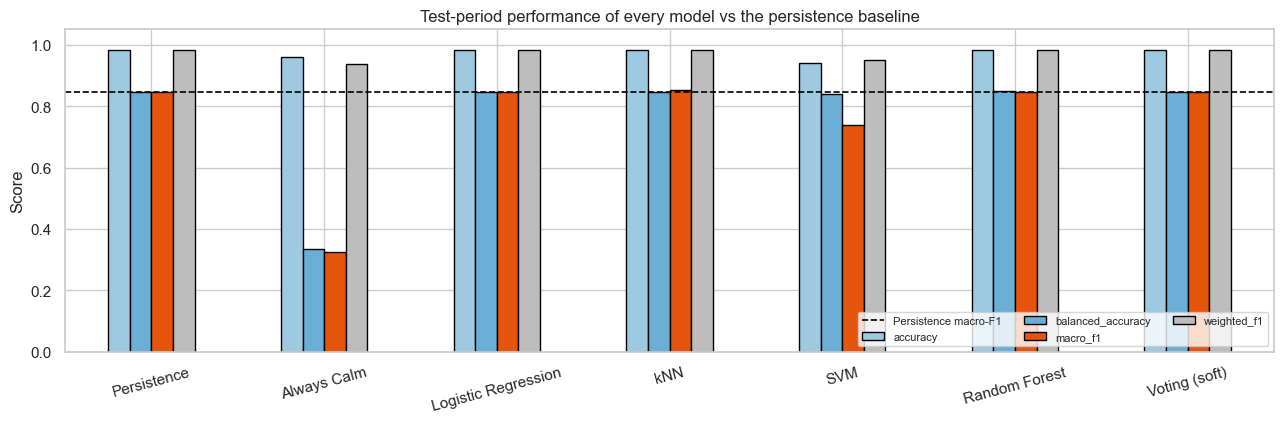

In [15]:
fig, ax = plt.subplots(figsize=(13, 4.4))
metrics_plot = test_metrics[["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1"]]
metrics_plot.plot(kind="bar", ax=ax, edgecolor="black", color=["#9ecae1", "#6baed6", "#e6550d", "#bdbdbd"])
ax.axhline(test_metrics.loc["Persistence", "macro_f1"], color="black", ls="--", lw=1.2, label="Persistence macro-F1")
ax.set_ylim(0, 1.05); ax.set_ylabel("Score"); ax.set_title("Test-period performance of every model vs the persistence baseline"); ax.legend(loc="lower right", ncol=3, fontsize=8)
ax.tick_params(axis="x", rotation=15)
save_fig("model_comparison")

precision                                   recall                                      f1                                  
regime                   Calm Stressed-Decline Stressed-Rebound   Calm Stressed-Decline Stressed-Rebound  Calm Stressed-Decline Stressed-Rebound
model                                                                                                                                           
Persistence              0.99             0.73             0.82   0.99             0.73             0.82  0.99             0.73             0.82
Always Calm              0.96             0.00             0.00   1.00             0.00             0.00  0.98             0.00             0.00
Logistic Regression      0.99             0.73             0.82   0.99             0.73             0.82  0.99             0.73             0.82
kNN                      0.99             0.74             0.85   0.99             0.73             0.82  0.99             0.74             0.83
SVM                      0.99             0.30             0.82   0.95             0.76             0.82  0.97             0.43             0.82
Random Forest            0.99             0.72             0.82   0.99             0.75             0.82  0.99             0.73             0.82
Voting (soft)            0.99             0.73             0.82   0.99             0.73             0.82  0.99             0.73             0.82

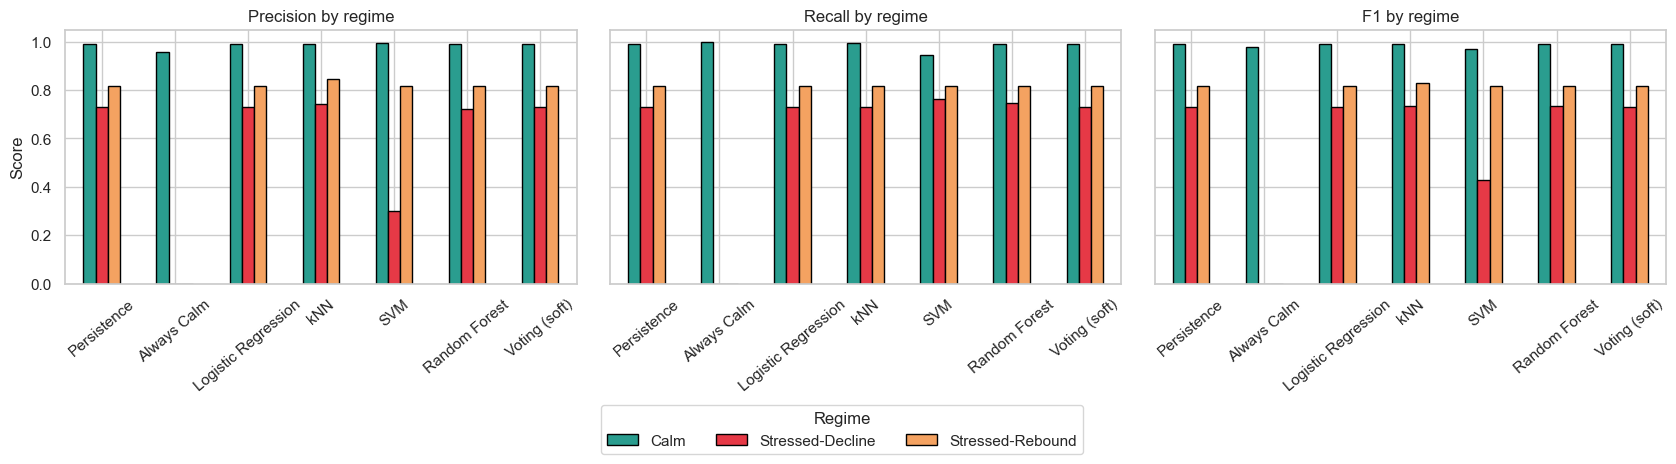

In [16]:
# Per-class precision / recall / F1 for every model
per_class = pd.concat({name: class_scores(y_t, pred[name]) for name in MODEL_ORDER}, names=["model", "regime"])
display(per_class[["precision", "recall", "f1", "support"]].round(3).unstack("regime")[["precision", "recall", "f1"]].round(2))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
for a_, met in zip(ax, ["precision", "recall", "f1"]):
    pc = per_class[met].unstack("regime").reindex(MODEL_ORDER)[[REGIME_NAMES[k] for k in CLASSES]]
    pc.plot(kind="bar", ax=a_, color=[COLORS[k] for k in CLASSES], edgecolor="black", legend=False)
    a_.set_title(met.capitalize() + " by regime"); a_.set_xlabel(""); a_.tick_params(axis="x", rotation=40)
ax[0].set_ylabel("Score"); ax[0].set_ylim(0, 1.05)
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORS[k], ec="black") for k in CLASSES], labels=NAMES, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.12), title="Regime")
save_fig("per_class_metrics")

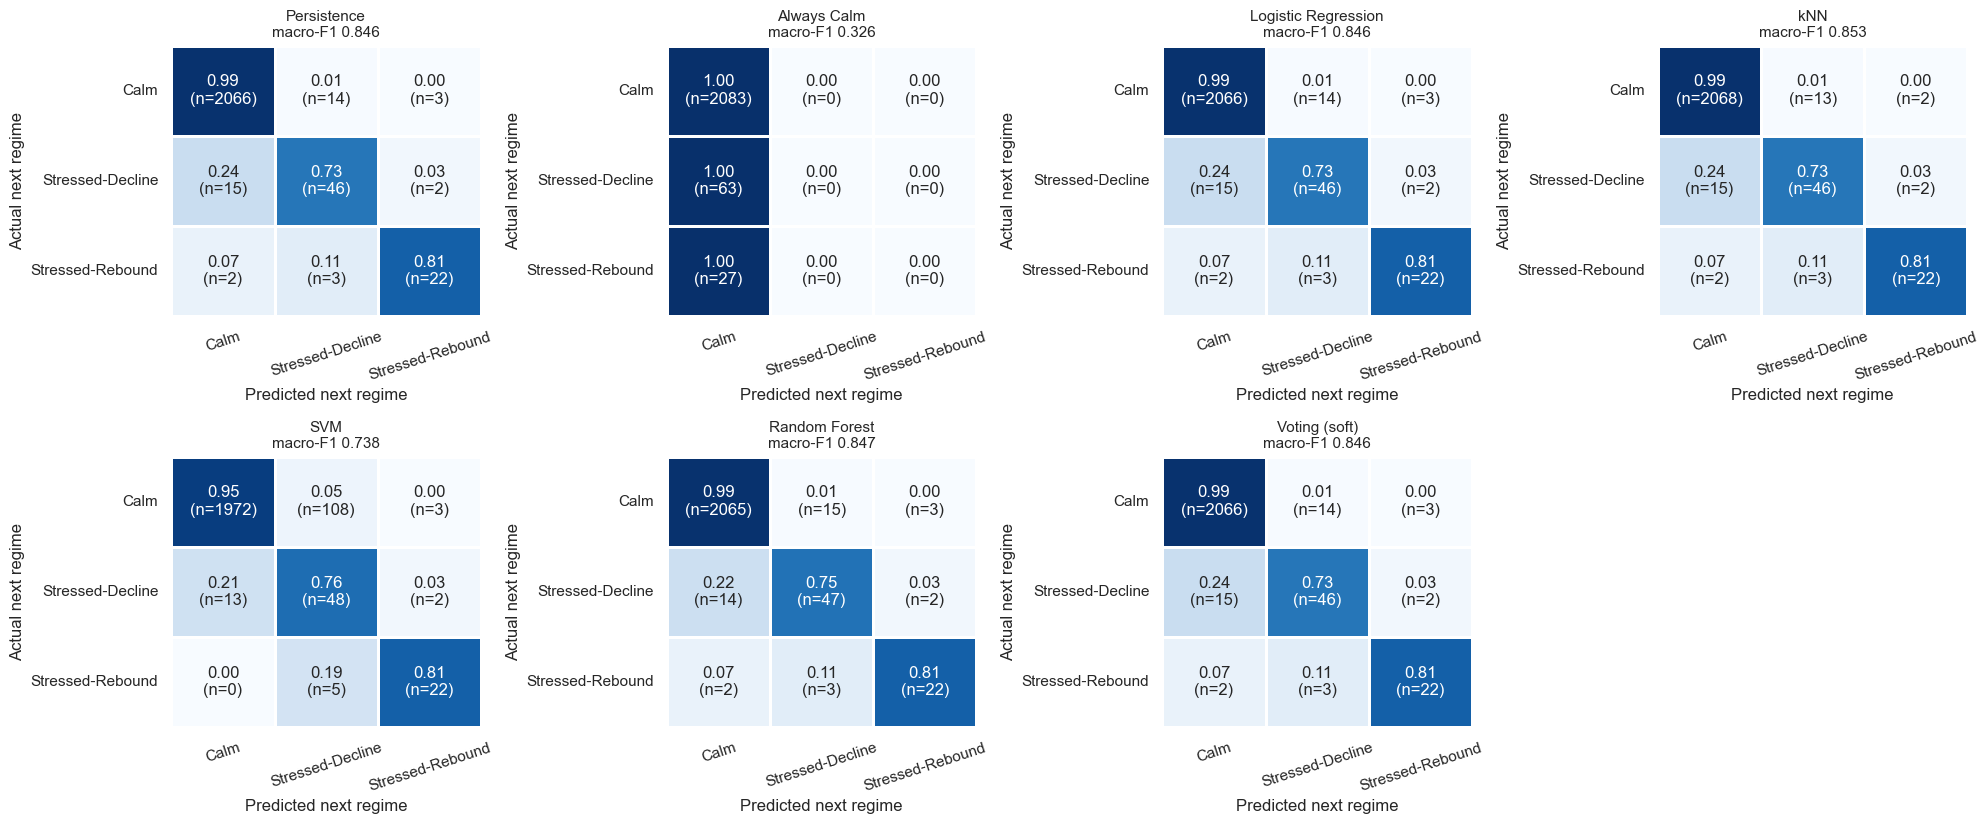

In [17]:
# Confusion matrices (rows = actual next regime, columns = predicted), row-normalised with counts
cms = {name: confusion_matrix(y_t, pred[name], labels=CLASSES) for name in MODEL_ORDER}
fig, axes = plt.subplots(2, 4, figsize=(20, 8.4))
for ax_, name in zip(axes.ravel(), MODEL_ORDER):
    cm = cms[name]; norm = cm / cm.sum(axis=1, keepdims=True)
    ann = np.array([[f"{norm[i, j]:.2f}\n(n={cm[i, j]})" for j in range(3)] for i in range(3)])
    sns.heatmap(norm, annot=ann, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax_, linewidths=1, linecolor="white")
    ax_.set_xticklabels(NAMES, rotation=18); ax_.set_yticklabels(NAMES, rotation=0)
    ax_.set_title(f"{name}\nmacro-F1 {test_metrics.loc[name, 'macro_f1']:.3f}", fontsize=11); ax_.set_xlabel("Predicted next regime"); ax_.set_ylabel("Actual next regime")
axes.ravel()[-1].axis("off")
save_fig("confusion_matrices")

In [18]:
# Binary view, derived from the same predictions (no refitting): is the NEXT day stressed (regime 1 or 2) or Calm?
rows = {}
for name in MODEL_ORDER:
    yb, pb, cb = (y_t > 0).astype(int), (pred[name] > 0).astype(int), (c_t > 0).astype(int)
    p, r, f, _ = precision_recall_fscore_support(yb, pb, labels=[1], zero_division=0)
    rows[name] = {"stressed precision": p[0], "stressed recall": r[0], "stressed F1": f[0], "balanced accuracy": balanced_accuracy_score(yb, pb),
                  "stress-entry recall (calm today, stressed tomorrow)": float(pb[(cb == 0) & (yb == 1)].mean()) if ((cb == 0) & (yb == 1)).any() else np.nan,
                  "stress-exit recall (stressed today, calm tomorrow)": float((1 - pb[(cb == 1) & (yb == 0)]).mean()) if ((cb == 1) & (yb == 0)).any() else np.nan}
    if name in proba:
        rows[name]["AUC of P(stressed)"] = roc_auc_score(yb, 1 - proba[name]["p_Calm"])
binary_metrics = pd.DataFrame(rows).T
print("BINARY VIEW: Calm vs Stressed (regimes 1+2 merged). Entry events:", int(((c_t == 0) & (y_t > 0)).sum()), "| exit events:", int(((c_t > 0) & (y_t == 0)).sum()))
display(binary_metrics.round(3))

BINARY VIEW: Calm vs Stressed (regimes 1+2 merged). Entry events: 17 | exit events: 17


,stressed precision,stressed recall,stressed F1,balanced accuracy,"stress-entry recall (calm today, stressed tomorrow)","stress-exit recall (stressed today, calm tomorrow)",AUC of P(stressed)
Persistence,0.811,0.811,0.811,0.901,0.000,0.000,NaN
Always Calm,0.000,0.000,0.000,0.500,0.000,1.000,NaN
Logistic Regression,0.811,0.811,0.811,0.901,0.000,0.000,0.977
kNN,0.830,0.811,0.820,0.902,0.000,0.118,0.911
SVM,0.410,0.856,0.554,0.901,0.235,0.000,0.959
Random Forest,0.804,0.822,0.813,0.907,0.059,0.000,0.978
Voting (soft),0.811,0.811,0.811,0.901,0.000,0.000,0.977



**Interpretation (test period, 2,173 samples):**

| | Accuracy | Balanced acc. | Macro-F1 | Delta macro-F1 vs persistence [95% CI] |
|---|---|---|---|---|
| Persistence | 0.982 | 0.846 | 0.846 | |
| Always Calm | 0.959 | 0.333 | 0.326 | |
| Logistic Regression | 0.982 | 0.846 | 0.846 | +0.000 [0.000, 0.000] |
| kNN | 0.983 | 0.846 | 0.853 | +0.007 [0.000, +0.032] |
| SVM | 0.940 | 0.841 | 0.738 | -0.108 [-0.165, -0.045] |
| Random Forest | 0.982 | 0.851 | 0.847 | +0.001 [-0.007, +0.014] |
| Voting (soft) | 0.982 | 0.846 | 0.846 | +0.000 [0.000, 0.000] |

1. **No model meaningfully outperforms persistence.** Logistic Regression and the Voting ensemble reproduce it exactly (their predictions are identical on all 2,173 days). kNN and Random Forest differ from persistence on 3 and 2 days respectively, giving macro-F1 gains of +0.007 and +0.001 whose intervals include or touch zero. **SVM is significantly worse** (-0.108): it predicts Stressed-Decline on 108 Calm days (precision 0.30 for that class), and catches a few more real changes at a very high false-alarm cost.
2. **Accuracy is uninformative here.** Always Calm already scores 95.9%, and the gap between 98.2% and 98.3% is 2 or 3 days. Macro-F1 and balanced accuracy separate the models from the trivial rule (0.33), but not from persistence.
3. **Which regimes are predicted best:** Calm (F1 0.99), then Stressed-Rebound (0.82) and Stressed-Decline (0.73). These numbers are the same for persistence, because the models mostly *are* persistence. The minority regimes are not ignored: once a stressed regime has started, persistence keeps predicting it.
4. **Which regimes are confused:** 15 of the 63 Stressed-Decline target days are predicted as Calm, and 2 of 27 Stressed-Rebound targets are predicted as Calm. In both cases the model failed to see the *start* of a stress episode. The reverse error (predicting a stressed regime when the market returns to Calm) is also common: 14 Calm target days are predicted Stressed-Decline, as the regime has just ended.
5. **Binary view (next day stressed or Calm):** persistence reaches a stressed F1 of 0.811 and no model improves it materially (kNN 0.820, Random Forest 0.813). SVM's stressed F1 is 0.554 (recall 0.86, precision 0.41). It catches 4 of the 17 entries into stress, but with 98 false calls.
6. **The test period is harder for persistence than validation** (macro-F1 0.846 against 0.894): the test stressed regimes were less persistent (Section 11), which is a property of 2020 being a short sharp episode.


## 11. Regime transition prediction

**Objective:** a next-regime model is only valuable if it helps when something *changes*. Persistence is right on 98.2% of test days precisely because it is silent about changes; the question is whether any model can anticipate a change without raising too many false alarms.

**Definitions (test period):**
- A **transition day** is a sample where the target differs from the current regime (`y(t+1) != R(t)`). There are **39** in the test period. A **stay day** is any other sample.
- **Change recall:** share of transition days on which the model predicts the *exact* new regime.
- **Change flagged:** share of transition days on which the model predicts *any* change (even to the wrong regime).
- **False-alarm rate:** share of stay days on which the model predicts a change.
- **Precision of change calls:** among all predicted changes, the share that were a correct change.
- **Ranking skill (probabilistic models):** the score `1 - P(current regime)` is the model's probability that the regime changes; its ROC-AUC and average precision measure whether it ranks transition days above stay days, independent of any threshold. A random ranking has AUC 0.5 and average precision equal to the base rate (1.8%).

Persistence has zero change recall by construction.

In [19]:
is_chg = y_t != c_t
TRANS_ORDER = ["Persistence", "Logistic Regression", "kNN", "SVM", "Random Forest", "Voting (soft)"]          # 'Always Calm' is not a transition forecaster
# benchmark that uses today's regime only: the training-period probability of leaving each regime (the Phase 7 matrix, training rows only)
stay_train = {k: float((tr_.loc[tr_["current_regime"] == k, "target_next_regime"] == k).mean()) for k in CLASSES}
markov_score = np.array([1 - stay_train[k] for k in c_t])
rng_ties = np.random.default_rng(SEED)

def recall_at_budget(score, budget):
    """Share of transition days among the top `budget` fraction of days ranked by score (ties broken at random, seed 42)."""
    order = np.argsort(-(score + rng_ties.uniform(0, 1e-9, len(score))))
    top = order[: int(round(budget * len(score)))]
    return float(is_chg[top].sum() / is_chg.sum())

rows = {}
for name in TRANS_ORDER:
    p = pred[name]; flagged = p != c_t
    correct_calls = flagged & (p == y_t)
    rec = {"transition days": int(is_chg.sum()),
           "change recall (exact new regime)": float(correct_calls[is_chg].mean()),
           "change flagged (any change)": float(flagged[is_chg].mean()),
           "changes predicted": int(flagged.sum()),
           "correct change calls": int(correct_calls.sum()),
           "precision of change calls": float(correct_calls.sum() / flagged.sum()) if flagged.sum() else np.nan,
           "false-alarm rate (stay days)": float(flagged[~is_chg].mean())}
    if name in proba:
        pcur = proba[name].to_numpy()[np.arange(len(c_t)), c_t]                      # probability assigned to staying in the current regime
        score = 1 - pcur
        rec["AUC of P(change)"] = roc_auc_score(is_chg, score)
        rec["average precision of P(change)"] = average_precision_score(is_chg, score)
        rec["transitions caught in top 5% of days"] = recall_at_budget(score, 0.05)
        rec["transitions caught in top 10% of days"] = recall_at_budget(score, 0.10)
    rows[name] = rec
rows["Regime-only benchmark (training exit rates)"] = {"transition days": int(is_chg.sum()), "AUC of P(change)": roc_auc_score(is_chg, markov_score),
    "average precision of P(change)": average_precision_score(is_chg, markov_score),
    "transitions caught in top 5% of days": recall_at_budget(markov_score, 0.05), "transitions caught in top 10% of days": recall_at_budget(markov_score, 0.10)}
trans_metrics = pd.DataFrame(rows).T
print("TRANSITION PREDICTION, test period. Base rate of a change:", round(float(is_chg.mean()) * 100, 2), "% of sessions")
print("Regime-only benchmark: probability of leaving each regime, estimated on TRAINING rows:", {REGIME_NAMES[k]: round(1 - v, 3) for k, v in stay_train.items()})
display(trans_metrics.round(3).T)

# the model followed in the detailed views is chosen from VALIDATION macro-F1 (training period), never from test results
trained = ["Logistic Regression", "kNN", "SVM", "Random Forest", "Voting (soft)"]
TOP_TRAINED = cv_summary.loc[trained, "macro_f1"].idxmax()
print("Model followed in the detailed views (highest validation macro-F1 among the trained models):", TOP_TRAINED)
types = pd.DataFrame({"actual": [f"{REGIME_NAMES[a]} -> {REGIME_NAMES[b]}" for a, b in zip(c_t[is_chg], y_t[is_chg])],
                      "model prediction for that day": [REGIME_NAMES[p] for p in pred[TOP_TRAINED][is_chg]]})
by_type = types.groupby("actual").size().to_frame("n")
by_type["correctly predicted (new regime)"] = [int(sum(types.loc[types["actual"] == k, "model prediction for that day"] == k.split(" -> ")[1])) for k in by_type.index]
by_type["predicted no change"] = [int(sum(types.loc[types["actual"] == k, "model prediction for that day"] == k.split(" -> ")[0])) for k in by_type.index]
print(f"Transition types in the test period and what {TOP_TRAINED} predicted on those days:")
display(by_type)

TRANSITION PREDICTION, test period. Base rate of a change: 1.79 % of sessions
Regime-only benchmark: probability of leaving each regime, estimated on TRAINING rows: {'Calm': 0.013, 'Stressed-Decline': 0.135, 'Stressed-Rebound': 0.074}


,Persistence,Logistic Regression,kNN,SVM,Random Forest,Voting (soft),Regime-only benchmark (training exit rates)
transition days,39.0,39.000,39.000,39.000,39.000,39.000,39.000
change recall (exact new regime),0.0,0.000,0.051,0.051,0.026,0.000,NaN
change flagged (any change),0.0,0.000,0.077,0.103,0.026,0.000,NaN
changes predicted,0.0,0.000,3.000,98.000,2.000,0.000,NaN
correct change calls,0.0,0.000,2.000,2.000,1.000,0.000,NaN
precision of change calls,NaN,NaN,0.667,0.020,0.500,NaN,NaN
false-alarm rate (stay days),0.0,0.000,0.000,0.044,0.000,0.000,NaN
AUC of P(change),NaN,0.781,0.677,0.861,0.927,0.908,0.767
average precision of P(change),NaN,0.114,0.151,0.070,0.268,0.122,0.157
transitions caught in top 5% of days,NaN,0.308,0.385,0.103,0.641,0.333,0.564


Model followed in the detailed views (highest validation macro-F1 among the trained models): Logistic Regression
Transition types in the test period and what Logistic Regression predicted on those days:


,n,correctly predicted (new regime),predicted no change
actual,,,
Calm -> Stressed-Decline,15,0,15
Calm -> Stressed-Rebound,2,0,2
Stressed-Decline -> Calm,14,0,14
Stressed-Decline -> Stressed-Rebound,3,0,3
Stressed-Rebound -> Calm,3,0,3
Stressed-Rebound -> Stressed-Decline,2,0,2


In [20]:
# Consistency check on the TRAINING-period validation folds: does the same ranking advantage over the regime-only benchmark appear there?
def oof_proba(make, X, y):
    P = np.zeros((len(y), 3))
    for a, b in SPLITS:
        m = make(); m.fit(X.iloc[a], y.iloc[a]); P[b] = m.predict_proba(X.iloc[b])
    return P

chg_va = (y_va != cur_va)
rows = {}
for kind in MODEL_KINDS:
    P = oof_proba(lambda kind=kind: make_model(kind, BEST_PARAMS[kind], proba=True), X_dev[FEATURE_SET], y_dev)[va_all]
    sc_ = 1 - P[np.arange(len(cur_va)), cur_va]
    order = np.argsort(-(sc_ + np.random.default_rng(SEED).uniform(0, 1e-9, len(sc_))))
    rows[kind] = {"AUC of P(change)": roc_auc_score(chg_va, sc_), "average precision": average_precision_score(chg_va, sc_),
                  "transitions caught in top 10% of days": float(chg_va[order[: int(0.1 * len(sc_))]].sum() / chg_va.sum())}
# regime-only benchmark inside each fold: exit rates estimated from that fold's own training block
bench_sc = np.zeros(len(y_dev))
for a, b in SPLITS:
    stay = {k: float((y_dev.iloc[a][cur_dev.iloc[a] == k] == k).mean()) for k in CLASSES}
    bench_sc[b] = [1 - stay[k] for k in cur_dev.iloc[b]]
bs = bench_sc[va_all]
order = np.argsort(-(bs + np.random.default_rng(SEED).uniform(0, 1e-9, len(bs))))
rows["Regime-only benchmark"] = {"AUC of P(change)": roc_auc_score(chg_va, bs), "average precision": average_precision_score(chg_va, bs),
                                 "transitions caught in top 10% of days": float(chg_va[order[: int(0.1 * len(bs))]].sum() / chg_va.sum())}
print("VALIDATION PERIOD (training data, pooled folds): ranking of 'regime changes tomorrow'. Transition days:", int(chg_va.sum()), "| base rate:", round(float(chg_va.mean()) * 100, 2), "%")
display(pd.DataFrame(rows).T.round(3))

VALIDATION PERIOD (training data, pooled folds): ranking of 'regime changes tomorrow'. Transition days: 47 | base rate: 2.27 %


,AUC of P(change),average precision,transitions caught in top 10% of days
Logistic Regression,0.827,0.160,0.468
kNN,0.641,0.039,0.255
SVM,0.775,0.048,0.149
Random Forest,0.845,0.072,0.170
Regime-only benchmark,0.791,0.061,0.170


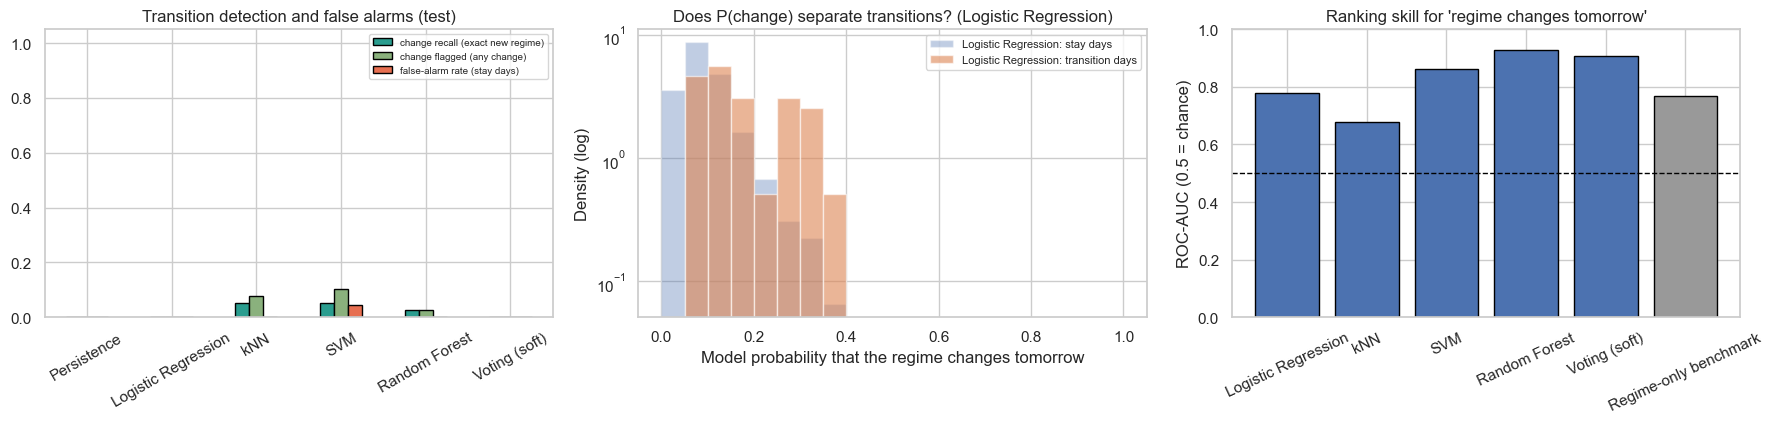

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))
tm = trans_metrics.loc[TRANS_ORDER, ["change recall (exact new regime)", "change flagged (any change)", "false-alarm rate (stay days)"]]
tm.plot(kind="bar", ax=ax[0], color=["#2a9d8f", "#8ab17d", "#e76f51"], edgecolor="black")
ax[0].set_ylim(0, 1.05); ax[0].set_title("Transition detection and false alarms (test)"); ax[0].tick_params(axis="x", rotation=30); ax[0].legend(fontsize=7)
cand = [n for n in trained if n in proba]
for n in cand:
    pcur = proba[n].to_numpy()[np.arange(len(c_t)), c_t]
    ax[1].hist(1 - pcur[~is_chg], bins=np.linspace(0, 1, 21), alpha=.35, density=True, label=f"{n}: stay days") if n == TOP_TRAINED else None
    ax[1].hist(1 - pcur[is_chg], bins=np.linspace(0, 1, 21), alpha=.6, density=True, label=f"{n}: transition days") if n == TOP_TRAINED else None
ax[1].set_yscale("log"); ax[1].set_xlabel("Model probability that the regime changes tomorrow"); ax[1].set_ylabel("Density (log)")
ax[1].set_title(f"Does P(change) separate transitions? ({TOP_TRAINED})"); ax[1].legend(fontsize=8)
bench_name = "Regime-only benchmark (training exit rates)"
auc = trans_metrics.loc[cand + [bench_name], "AUC of P(change)"]
ax[2].bar([n if n != bench_name else "Regime-only benchmark" for n in auc.index], auc.to_numpy(), color=["#4c72b0"] * len(cand) + ["#999999"], edgecolor="black"); ax[2].axhline(.5, color="black", ls="--", lw=1)
ax[2].set_ylim(0, 1); ax[2].set_ylabel("ROC-AUC (0.5 = chance)"); ax[2].set_title("Ranking skill for 'regime changes tomorrow'"); ax[2].tick_params(axis="x", rotation=25)
save_fig("transition_analysis")


**Interpretation (regime transitions, test period, 39 transition days):**

- **Models predict persistence even when a transition occurs.** Logistic Regression and the Voting ensemble flag **no** change at all. kNN flags 3 changes (2 correct), Random Forest 2 (1 correct), and SVM 98 (2 correct, precision 2%). Exact change recall is 0% to 5% for every model, against 0% for persistence by construction, and the false-alarm rate is about 0% except for SVM (4.4%). The transitions that are hardest are exactly the most important ones: **none of the 15 Calm to Stressed-Decline entries and none of the 14 returns to Calm are anticipated by the model that was selected on validation** (Logistic Regression).
- **Why the selected models flag no changes:** for Logistic Regression (shown in the histogram) and for the Voting ensemble the probability of a change never exceeds 0.39 (it is higher on transition days than on stay days, but never reaches 0.5), so the arg-max prediction is always "stay". The other models do cross 0.5 occasionally: kNN on 3 days, Random Forest on 4 and SVM on 69 (the SVM class prediction itself flags 98, because the SVM's class decision and its calibrated probabilities are computed differently). Whether a *threshold below 0.5* would help is an extra decision rule; I did not add one because it would have to be tuned on a validation set with 47 changes.
- **Ranking skill is mixed and not consistent across periods.** On the test period the Random Forest's probability of change has the best ranking (ROC-AUC 0.927, average precision 0.268; the 1.8% base rate is the chance level of average precision), and its top 10% of days contain 79.5% of the transitions, against 56.4% for a benchmark that uses today's regime alone (the training exit rates: 1.3% from Calm, 13.5% from Stressed-Decline, 7.4% from Stressed-Rebound). **But on the validation folds the same model has no advantage** (top 10% catches 17.0% in both cases; AUC 0.845 against 0.791), while Logistic Regression looks best in validation (top 10%: 46.8%) and the lowest of the five models in test (41.0%, below the 56.4% benchmark). Rankings that change sign between two periods, with 47 and 39 events from two crises, are not evidence of real skill.
- **A large part of what looks like skill is just "stressed today".** 22 of the 39 test transitions (56.4%) start from a regime that is already stressed, and the regime-only benchmark ranks those days first without using any market feature. Only the 17 entries from Calm are genuinely hard, and no model gets more than 1 of them right at the arg-max.
- **Some regimes are more predictable than others:** Calm is the most stable (daily exit rate about 1%), so its next-day regime is predicted well simply by persistence; Stressed-Decline is the least predictable (13.5% daily exit rate in training, 27% in test), and its exits are not anticipated.


## 12. Model interpretation and financial relevance

**Objective:** see which inputs drive the predictions and whether the models capture market behaviour or just the persistence of regimes.

**Method and why it differs by model** (the two measures are not comparable):
- **Logistic Regression:** the coefficients are the effect of a one-standard-deviation increase of each input on the log-odds of each class (the inputs were standardised in the pipeline). Signs are meaningful, and PC coefficients can be translated back to the original 21 features using the PCA loadings. These are **associations in the fitted linear model**, not causal effects.
- **Random Forest:** impurity-based importance (how much a variable reduces node impurity in training) is biased toward high-variance inputs, so it is complemented by **permutation importance on the test period** (the drop in macro-F1 when one input is shuffled). Correlated inputs share importance, and permutation importance on a handful of events is noisy.

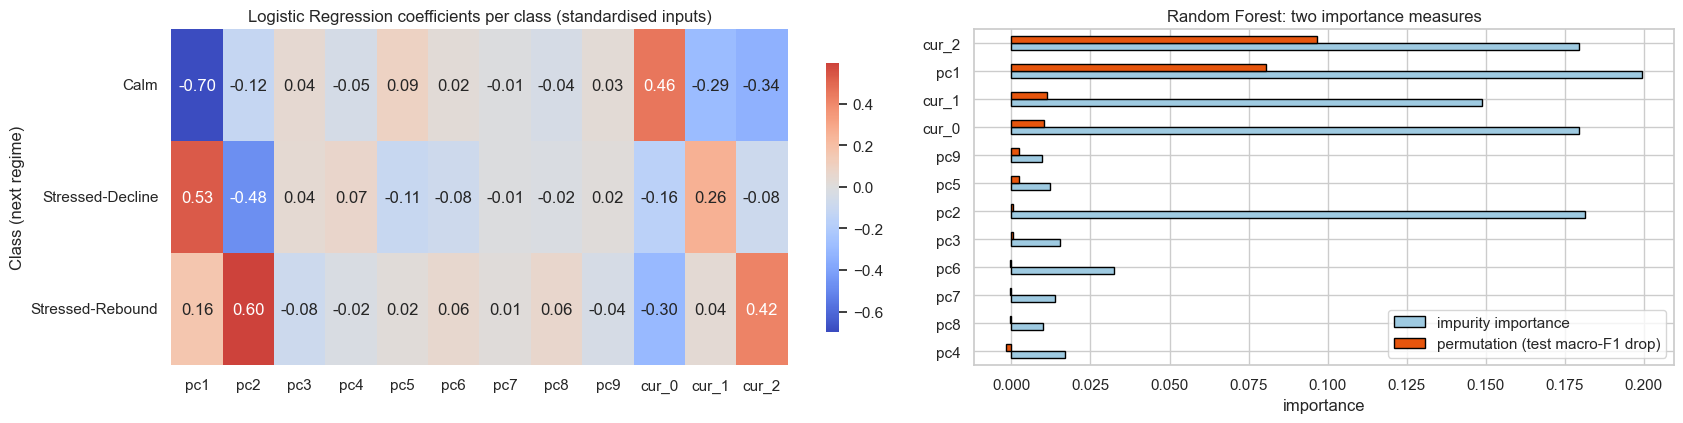

Random Forest importances (sorted by permutation importance on the test period):


,impurity importance,permutation (test macro-F1 drop)
cur_2,0.1794,0.0967
pc1,0.1995,0.0804
cur_1,0.1490,0.0113
cur_0,0.1796,0.0104
pc9,0.0098,0.0024
pc5,0.0123,0.0024
pc2,0.1815,0.0005
pc3,0.0155,0.0004
pc6,0.0325,-0.0004
pc7,0.0138,-0.0004


Logistic Regression: effect of each ORIGINAL feature on the log-odds of each next regime (through the PCs only)
Top 5 negative and positive for 'Stressed-Decline tomorrow':


effect
most negative nifty_ret_21d      -0.150
              nifty_ma_gap_63d   -0.147
              nifty_ma_gap_21d   -0.128
              sp500_ret_21d      -0.120
              banknifty_rel_21d  -0.074
most positive nifty_vol_10d       0.035
              stock_corr_21d      0.056
              us10y_level         0.070
              repo_change_63d     0.070
              usdinr_ret_21d      0.106

Coefficients on the current-regime inputs (row = class predicted for tomorrow):


,today: Calm,today: Stressed-Decline,today: Stressed-Rebound
Calm,0.46,-0.29,-0.34
Stressed-Decline,-0.16,0.26,-0.08
Stressed-Rebound,-0.30,0.04,0.42


In [22]:
lr = final_models["Logistic Regression"]
coef = pd.DataFrame(lr.named_steps["clf"].coef_, index=NAMES, columns=X_train.columns)
fig, ax = plt.subplots(1, 2, figsize=(17, 4.4), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(coef, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[0], cbar_kws={"shrink": .8})
ax[0].set_title("Logistic Regression coefficients per class (standardised inputs)"); ax[0].set_ylabel("Class (next regime)")

rf = final_models["Random Forest"]
rf_imp = pd.DataFrame({"impurity importance": rf.feature_importances_}, index=X_train.columns)
perm = permutation_importance(rf, X_test, y_test, scoring=make_scorer(f1_score, labels=CLASSES, average="macro", zero_division=0), n_repeats=10, random_state=SEED, n_jobs=1)
rf_imp["permutation (test macro-F1 drop)"] = perm.importances_mean
rf_imp.sort_values("permutation (test macro-F1 drop)").plot(kind="barh", ax=ax[1], color=["#9ecae1", "#e6550d"], edgecolor="black")
ax[1].set_title("Random Forest: two importance measures"); ax[1].set_xlabel("importance")
save_fig("interpretation")
print("Random Forest importances (sorted by permutation importance on the test period):")
display(rf_imp.sort_values("permutation (test macro-F1 drop)", ascending=False).round(4))

# express the Logistic Regression effects in terms of the ORIGINAL standardised features
if FEATURE_SET.startswith("B") or FEATURE_SET.startswith("A"):
    pc_part = coef[PC_COLS] / lr.named_steps["scale"].scale_[: len(PC_COLS)]                         # effect per raw PC unit
    w_orig = pd.DataFrame(pc_part.to_numpy() @ pca_p6.components_, index=NAMES, columns=FEATURE_COLS)   # effect per 1 sd of each ORIGINAL feature
    how = "through the PCs only"
else:
    w_orig = coef[FEATURE_COLS]; how = "directly (inputs are the original standardised features)"
print(f"Logistic Regression: effect of each ORIGINAL feature on the log-odds of each next regime ({how})")
print("Top 5 negative and positive for 'Stressed-Decline tomorrow':")
s_ = w_orig.loc["Stressed-Decline"].sort_values()
display(pd.concat({"most negative": s_.head(5), "most positive": s_.tail(5)}).round(3).to_frame("effect"))
if all(c in coef.columns for c in CUR_COLS):
    print("Coefficients on the current-regime inputs (row = class predicted for tomorrow):")
    display(coef[CUR_COLS].rename(columns={f"cur_{k}": f"today: {REGIME_NAMES[k]}" for k in CLASSES}).round(2))

Share of test predictions identical to the persistence forecast:


,share of predictions equal to today's regime
Always Calm,0.9586
Logistic Regression,1.0000
kNN,0.9986
SVM,0.9549
Random Forest,0.9991
Voting (soft),1.0000


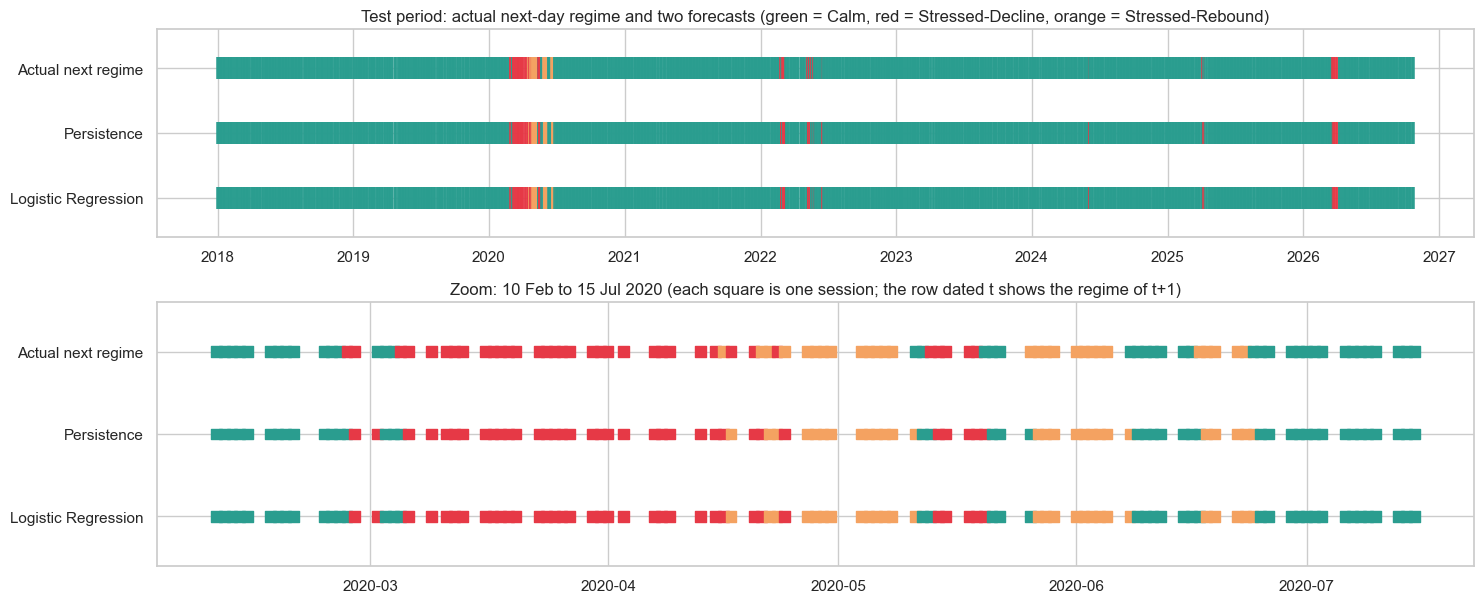

In [23]:
# Do the models mostly repeat today's regime?
agree = pd.Series({n: float((pred[n] == c_t).mean()) for n in MODEL_ORDER[1:]}, name="share of predictions equal to today's regime")
print("Share of test predictions identical to the persistence forecast:")
display(agree.to_frame().round(4))

# actual vs predicted over time: the full test period, plus the March-June 2020 episode in detail
cmap = lambda s: [COLORS[v] for v in s]
show_models = ["Persistence", TOP_TRAINED]
fig, ax = plt.subplots(2, 1, figsize=(15, 6.2), gridspec_kw={"height_ratios": [1.1, 1.4]})
rows_ = [("Actual next regime", y_t)] + [(n, pred[n]) for n in show_models]
for i, (lab, vals) in enumerate(rows_):
    ax[0].scatter(te_.index, np.full(len(vals), len(rows_) - 1 - i), c=cmap(vals), marker="|", s=250, linewidths=1.1)
ax[0].set_yticks(range(len(rows_))); ax[0].set_yticklabels([r[0] for r in rows_][::-1]); ax[0].set_ylim(-.6, len(rows_) - .4)
ax[0].set_title("Test period: actual next-day regime and two forecasts (green = Calm, red = Stressed-Decline, orange = Stressed-Rebound)")
zm = (te_.index >= "2020-02-10") & (te_.index <= "2020-07-15")
tix = te_.index[zm]
for i, (lab, vals) in enumerate(rows_):
    ax[1].scatter(tix, np.full(zm.sum(), len(rows_) - 1 - i), c=cmap(np.asarray(vals)[zm]), marker="s", s=60)
ax[1].set_yticks(range(len(rows_))); ax[1].set_yticklabels([r[0] for r in rows_][::-1]); ax[1].set_ylim(-.6, len(rows_) - .4)
ax[1].set_title("Zoom: 10 Feb to 15 Jul 2020 (each square is one session; the row dated t shows the regime of t+1)")
save_fig("actual_vs_predicted")


**Interpretation (what the models appear to use):**
- **The models mostly encode persistence.** Logistic Regression and Voting predict today's regime on 100% of test days, kNN on 99.86%, Random Forest on 99.91%. The only model that frequently departs from persistence (SVM, 95.5% agreement) is the one that does worse.
- **Logistic Regression** (heavily regularised, `C = 0.01`): the largest coefficients are on **`pc1` (the stress axis) and `pc2` (the trend axis)**: `pc1` is -0.70 for tomorrow-Calm and +0.53 for tomorrow-Stressed-Decline, and `pc2` is +0.60 for tomorrow-Stressed-Rebound and -0.48 for tomorrow-Stressed-Decline. These are the two axes that define the regimes, so the model is largely re-learning the K-Means rule (higher stress score means stressed; falling trend means Decline, rising trend means Rebound). The current-regime inputs come next and are positive on the diagonal (today Calm raises tomorrow-Calm by 0.46, today Stressed-Decline raises tomorrow-Stressed-Decline by 0.26, today Stressed-Rebound raises tomorrow-Stressed-Rebound by 0.42): that is persistence. The other PCs have small coefficients (at most 0.11 in absolute value). Translated back to the original features, higher 21-day Nifty return, higher gap to the 63 and 21-day averages and higher S&P 500 return lower the odds of Stressed-Decline tomorrow (-0.12 to -0.15 per standard deviation), while a higher 21-day USD/INR return (+0.11), repo-rate change and US 10-year yield raise them. These signs are plausible (weak prices and a weakening rupee go with stress), but they are small **associations in the fitted model, not causal effects**, and `us10y_level` and `repo_change_63d` are the two Phase 5 features with a calendar-like character.
- **Random Forest:** the permutation importance on the test period is concentrated in `cur_2` (current regime Stressed-Rebound, macro-F1 drop 0.097) and `pc1` (the stress axis, 0.080); the other current-regime indicators matter a little (0.010 to 0.011) and the other PCs essentially nothing. The impurity importance spreads over `pc1`, `pc2` and the regime indicators (0.15 to 0.20 each). The two measures disagree on `pc2`, as impurity importance favours high-variance inputs; and permutation importance on a few events is noisy and shares credit between correlated inputs.
- **Does the model capture market behaviour or only persistence?** Mostly persistence, plus a re-learned version of the regime rule. The market variables that carry weight are the ones that define the regimes in the first place (`pc1` in both models, `pc2` in Logistic Regression), and the current-regime indicators carry the rest. None of this is a signal that a *change* is coming: the resulting predictions equal today's regime on 99.9% to 100% of test days. The time plot makes the picture concrete: in the 2020 zoom, the persistence forecast is simply the actual series delayed by one session, and Logistic Regression is indistinguishable from it.
- **Relevance for the trading and risk system:** if the next-day regime is mostly today's regime, a risk overlay can apply today's regime to tomorrow directly (the outline's S1 rule) without a classifier. The models give no evidence of useful lead time.


## 13. Saving the Phase 8 outputs

Predictions carry the date of the **features** (day *t*), the **target date** (*t+1*), the current regime, the actual next regime, and each model's forecast, so Phase 9 can align them with market returns. **Phase 9 must treat the forecast for *t+1* as known at the close of *t*.** The model bundle stores everything needed to reproduce a forecast from the raw 21 features (Phase 6 scaler, PCA, K-Means and relabelling map, plus the classifier and its input order), so the app in Phase 10 can load it without retraining.

In [24]:
# --- prepared classification dataset (inputs of every candidate feature set + target) ---
dataset_out = dataset.join(design[FEATURE_SET])               # day-t inputs of the chosen feature set + current regime, target date and target
dataset_out.round(6).to_csv(PROC / "next_regime_dataset.csv", index_label="Date")

# --- test-period predictions ---
pred_out = pd.DataFrame({"target_date": te_["target_date"], "current_regime": c_t, "actual_next_regime": y_t,
                         "actual_next_regime_name": y_test.map(REGIME_NAMES).to_numpy()}, index=te_.index)
for name in MODEL_ORDER:
    pred_out[f"pred_{name.replace(' ', '_').replace('(', '').replace(')', '')}"] = pred[name]
for name in trained:
    for col in proba[name].columns:
        pred_out[f"prob_{name.replace(' ', '_').replace('(', '').replace(')', '')}_{col[2:]}"] = proba[name][col].round(6)
pred_out.to_csv(PROC / "next_regime_predictions_test.csv", index_label="Date")

# --- metrics ---
test_metrics.round(6).to_csv(PROC / "next_regime_metrics_test.csv", index_label="model")
per_class.round(6).to_csv(PROC / "next_regime_per_class_metrics_test.csv")
binary_metrics.round(6).to_csv(PROC / "next_regime_binary_metrics_test.csv", index_label="model")
trans_metrics.round(6).to_csv(PROC / "next_regime_transition_metrics_test.csv", index_label="model")
pd.concat({n: pd.DataFrame(cms[n], index=[f"actual {x}" for x in NAMES], columns=[f"pred {x}" for x in NAMES]) for n in MODEL_ORDER}, names=["model"]).to_csv(PROC / "next_regime_confusion_matrices_test.csv")
cv_results.assign(chosen=lambda d: [(r["feature_set"] == FEATURE_SET) and (json.loads(r["params"]) == BEST_PARAMS[r["model"]]) for _, r in d.iterrows()]).round(6).to_csv(PROC / "next_regime_cv_results.csv", index=False)
cv_summary.round(6).to_csv(PROC / "next_regime_validation_summary.csv", index_label="model")

# --- models and configuration ---
config = {"seed": SEED, "target": "regime at t+1 from features at close of t", "feature_set": FEATURE_SET, "input_columns": list(X_train.columns),
          "classes": CLASSES, "class_names": REGIME_NAMES, "best_params": BEST_PARAMS, "ensemble_members": ENSEMBLE_MEMBERS,
          "validation": f"TimeSeriesSplit({N_SPLITS}) expanding window, pooled out-of-fold macro-F1", "train_rows": len(X_train), "test_rows": len(X_test),
          "train_target_dates": [str(y_train.index.min().date()), str(tr_["target_date"].max().date())],
          "relabel_from_kmeans_raw": RELABEL, "timing_note": "forecast for t+1 is known at the close of t"}
with open(PROC / "next_regime_model_config.json", "w") as f:
    json.dump(config, f, indent=2, default=str)
for name, m in final_models.items():
    joblib.dump(m, MODELS / f"next_regime_{name.replace(' ', '_').replace('(', '').replace(')', '').lower()}.joblib")
joblib.dump({"classifier_by_name": final_models, "scaler": scaler_p6, "pca": pca_p6, "kmeans": kmeans_p6, "relabel": RELABEL, "config": config},
            MODELS / "next_regime_bundle.joblib")

# --- final checks ---
chk_pred = pd.read_csv(PROC / "next_regime_predictions_test.csv", index_col="Date", parse_dates=True)
assert chk_pred.index.equals(te_.index) and chk_pred.index.is_monotonic_increasing and chk_pred.index.is_unique
assert chk_pred.isna().sum().sum() == 0
assert (chk_pred["actual_next_regime"].to_numpy() == regimes["regime"].loc[pd.to_datetime(chk_pred["target_date"])].to_numpy()).all()
assert (pd.to_datetime(chk_pred["target_date"]) > chk_pred.index).all()
reload_ = joblib.load(MODELS / "next_regime_bundle.joblib")
re_pred = reload_["classifier_by_name"][TOP_TRAINED].predict(X_test)
assert (re_pred == pred[TOP_TRAINED]).all(), "reloaded model does not reproduce its predictions"
assert (pd.read_csv(PROC / "regimes.csv", index_col="Date", parse_dates=True)["regime"].equals(regimes["regime"]))
saved = sorted(p.name for p in PROC.glob("next_regime_*")) + sorted(p.name for p in MODELS.glob("next_regime_*"))
print("All checks passed: predictions aligned with dates and targets, bundle reloads and reproduces its forecasts, regimes.csv untouched.")
print("Saved:", *saved, sep="\n  ")

All checks passed: predictions aligned with dates and targets, bundle reloads and reproduces its forecasts, regimes.csv untouched.
Saved:
  next_regime_binary_metrics_test.csv
  next_regime_confusion_matrices_test.csv
  next_regime_cv_results.csv
  next_regime_dataset.csv
  next_regime_metrics_test.csv
  next_regime_model_config.json
  next_regime_per_class_metrics_test.csv
  next_regime_predictions_test.csv
  next_regime_transition_metrics_test.csv
  next_regime_validation_summary.csv
  next_regime_bundle.joblib
  next_regime_knn.joblib
  next_regime_logistic_regression.joblib
  next_regime_random_forest.joblib
  next_regime_svm.joblib
  next_regime_voting_soft.joblib



## 14. Final Phase 8 report

**1. What was the exact prediction problem?** Predict the regime (Calm, Stressed-Decline, Stressed-Rebound) of trading day *t+1* from information available at the close of day *t*, on the Phase 6 labels, with a chronological split (train 2008-2017, test 2018-October 2026) and a comparison against the "tomorrow = today" persistence baseline.

**2. How was the target built?** `target = regime.shift(-1)`, with the last session dropped (4,509 rows to 4,508), verified against an independent date lookup. Samples are assigned to train or test by **target date**, so the row dated 2017-12-29 (which predicts 2018-01-02) is a test sample. Result: 2,335 training and 2,173 test samples; 68 and 39 regime changes.

**3. Which features, and why?** The 9 Phase 6 PCA scores of the day-*t* feature table plus the one-hot of the current regime (feature set B). Chosen on training-period chronological validation over four candidates (PCs; PCs + current regime; 21 standardised features; 21 features + current regime), mean best macro-F1 0.846 against 0.640, 0.668 and 0.793. PCs because they are the space in which the regimes were defined and are decorrelated; the current regime because persistence is the dominant information and including it makes persistence a special case of the model. Excluded: anything dated after *t*, forward-looking Phase 7 variables, distances to K-Means centres (a possible next step), `split`, prices and identifiers.

**4. How was look-ahead bias prevented?** Inputs are functions of day-*t* data only (verified row by row), the target is the next row's regime, no training label comes from the test period, the Phase 6 scaler/PCA/K-Means were fitted on 2008-2017, the extra scaler sits inside the model pipeline and is fitted per training fold, tuning used only expanding-window validation inside the training period, and the test period was used once. **Residual caveat:** the regime labels are in-sample for the training period, so validation scores inside it are optimistic about the regime definition; only the test scores are genuinely out-of-sample.

**5. Which models and why?** The set in the outline: Logistic Regression, kNN, SVM (RBF), Random Forest, and a soft Voting ensemble of the three best by validation. They cover a linear, a local, a margin-based and a tree-based view of the data, with small grids because there are only 107 regime changes. More flexible models (boosting, neural networks, HMM) were not justified by this amount of event data.

**6. Performance against persistence (test, macro-F1):** persistence 0.846; Logistic Regression 0.846 and Voting 0.846 (identical predictions); kNN 0.853 (+0.007, 95% CI [0.000, +0.032]); Random Forest 0.847 (+0.001, [-0.007, +0.014]); SVM 0.738 (-0.108, [-0.165, -0.045]). **No model reliably beats persistence.**

**7. Best model, considering more than accuracy:** *statistically*, kNN has the highest test macro-F1 (0.853) but the improvement is 2 or 3 days out of 2,173 and its interval touches zero, so it is not distinguishable from persistence. By validation, Logistic Regression and persistence tie (0.894). The only model that is clearly different is SVM, and it is worse.

**8. Transitions:** poor. Exact change recall is 0% to 5% (39 transition days); the validation-selected Logistic Regression and the Voting ensemble never predict a change; kNN gets 2 of 39 and Random Forest 1 of 39 right; SVM gets 2 of 39 with 98 changes predicted. Calm to Stressed-Decline entries (15) and returns to Calm (14) are never anticipated by the selected model. The Random Forest's probability of change ranks transitions well on the test period (AUC 0.93), but this advantage over a regime-only benchmark does not appear on the validation folds, so it is not reliable.

**9. Major limitations:** only 107 regime changes in total (39 in test) and 90 stressed test days, from essentially two crises; Stressed-Rebound has 27 test days from one episode; labels are in-sample for training and defined relative to 2008-09 (Phase 7.4); validation can barely observe Stressed-Rebound and has 47 changes; the models were given no engineered boundary-proximity features (distances to K-Means centres or changes in the PCs), which is the most obvious route to anticipating changes and a clear next step; the grids are small and their optima sit at the edges; no decision threshold below 0.5 was tuned; the test period was used for permutation importance (descriptive only).

**10. Is a model suitable to carry forward into Phase 9?**
- **Statistically best:** kNN by test macro-F1, but not distinguishable from persistence.
- **Most appropriate for the project:** the **persistence rule**, i.e. applying the regime known at the close of *t* to day *t+1*, which is exactly the outline's S1 strategy. It is simple, it cannot be beaten reliably by any model here, and the validation-selected Logistic Regression and Voting classifiers reproduce it exactly.
- **What to carry forward:** `regimes.csv` and the persistence rule for S0/S1 and the VaR work; the saved classifiers and predictions only for completeness, and for the optional classifier-driven backtest, which would be identical to S1 for Logistic Regression and Voting and almost identical for kNN and Random Forest, so it is not informative. The Random Forest probability of change could be tried as an optional early-warning input, but its evidence is inconsistent and it should be presented as exploratory.
- **What Phase 9 should expect:** the regime is only known at the close of *t*, the first leg of a fall is not anticipated (Phase 7: detection lag of 5% to 8% in the Nifty), Stressed-Decline flickers, and stress has been followed by higher average returns, so the overlay has to be tested after costs and not assumed to help.

**Overall verdict:** Phase 8 is complete and its outputs are validated. The honest result is **negative**: next-day regime classification adds no reliable predictive value beyond persistence on this data, and the regimes are best used as a description of the *current* market state.
